<div align="center"> 

---



# **Cerebellum Mega Analysis**


<img src="https://static.wixstatic.com/media/da4857_5f6dbdb6bbd84328b1e31c7f2dafb673~mv2.png/v1/fill/w_224,h_226,al_c,q_85,usm_0.66_1.00_0.01,enc_auto/enigma_addiction-300x249.png" alt="image" style="width:300px;"/>


 </img>
</div>


---
# <u> **Project Description:**</u>

The aim of this study is to perform a multi-site mega/meta analysis to asses the effects of substance use on volumetric changes in cerebellar regions (and far beyond). 

## **Hypothesis to test**

**Variables to consider:** 
  - Age
  - Sex
  - Polysubstance use : Smoke and alcohol
  
  
  **Analysis:**
   1. Volume comparisons between-groups of:
   - cerebellum subcortical regions
   - cerebellum cortical regions

2. Main effects in multiple regressions:
- Cerebellar volume ~ time of consume
- Cerebellar volume ~ drug type

3. Interaction effects: Cerebellum volume
- group * sex
- group * age * sex

---

In [1]:
addTaskCallback(function(...) {set.seed(42);TRUE})
options(warn=-1) # to turn off warnings
#options(warn=0) # to turn on warnings

1 
1

### Load Packages

In [2]:
# Load required packages  
  pacman::p_load(tidyverse,sparklyr,magrittr,lubridate,standardize,reshape2,broom,colorspace,tableone,ggridges,
    PTCA4CATA,corrplot,viridis,TExPosition,broom,ggpubr,ggdist,ggseg,data4PCCAR,foreach,doParallel)

In [3]:
theme_output  <- theme(text = element_text(family = "Times New Roman"),
                        axis.text.x = element_text(size = 20),
                        axis.text.y = element_text(size = 20),
                        axis.title.x = element_text(size = 25),
                        axis.title.y = element_text(size = 25),
                        legend.text = element_text(size = 22), legend.title = element_text(size = 24),
                        title = element_text(size = 20,face = "italic"))

pal_sex <- c(alpha("#8E5A9C",1),alpha("#2879BC",1))
pal_user <- c(alpha("#757575",1),alpha("#059DC7",1))
pal_substances <- c(alpha("#757575",1),alpha("#C93F4D",1),alpha("#EB8F33",1),alpha("#0B8755",1),
    alpha("#3A5589",1),alpha("#764EA1",1))

# size_colors <- colorRampPalette(c("#1c90bf","#ffffff","#eb8a3d"),space = "rgb")(100)
size_colors <- colorRampPalette(c("#3e196e", "#d46c76", "#ffc07c"),space = "rgb")(28)
common_gradient_scale <- scale_fill_gradientn(colours = size_colors, na.value = "#E7E7E7")

In [4]:
`%notin%` <- Negate(`%in%`)

### Load Rdata

In [5]:
setwd("/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum/")

In [6]:
load("Data/RData/Volumes_Cerebellum.RData")

# Brain-Cerebellum association (PLS): Acapulco - DK

## Preparation

In [14]:
# Select only the columns that contain the volume of the cerebellum and cerebrum
Acapulco_volumes <- Volumes_Cerebellum_Acapulco_Harmonized %>% select(ID_MRI, Substance, contains("."))
DK_volumes <- Volumes_Cerebral_DK_Harmonized %>% select(ID_MRI, Substance, contains("_")) 

In [15]:
substances <- unique(Volumes_Cerebellum_Acapulco_Harmonized$Substance)

In [16]:
#Merge both databases to match the same amount of subjects
merged_acapulco_DK_volumes <- Acapulco_volumes %>% left_join(DK_volumes) %>% drop_na() %>% 
    mutate(ID_MRI = factor(ID_MRI),
    group = if_else(Substance == "HC",0,1) %>%
        factor(labels = c("HC","User")),
    Substance = factor(Substance, levels = c("HC","ALC", "ATS", "CANN", "COC", "NIC"))) %>% 
    unique() %>%
    filter(!is.na(Substance)) %>% 
    filter(complete.cases(.))

Joining with `by = join_by(ID_MRI, Substance)`


In [17]:
Acapulco_volumes_only <- merged_acapulco_DK_volumes %>% select(contains(".")) 
DK_volumes_only <- merged_acapulco_DK_volumes %>% select(contains("h_"))

In [18]:
boot_perm=1000
nIter=1000
split_tt=100

## Correlation and SVD decomposition

### Correlation between metrics

In [19]:
##getting the z-scores
Acapulco_volumes_only_z <- merged_acapulco_DK_volumes %>% select(contains(".")) %>% 
    scale(center = TRUE, scale = TRUE) 
DK_volumes_only_z <- merged_acapulco_DK_volumes %>% select(contains("h_")) %>% 
    scale(center = TRUE, scale = TRUE)

###preparing the Spearman correlation matrices
Acapulco_volumes_only_z_cor <- cor(Acapulco_volumes_only_z, method = "pearson")

DK_volumes_only_z_cor <- cor(DK_volumes_only_z, method = "pearson")

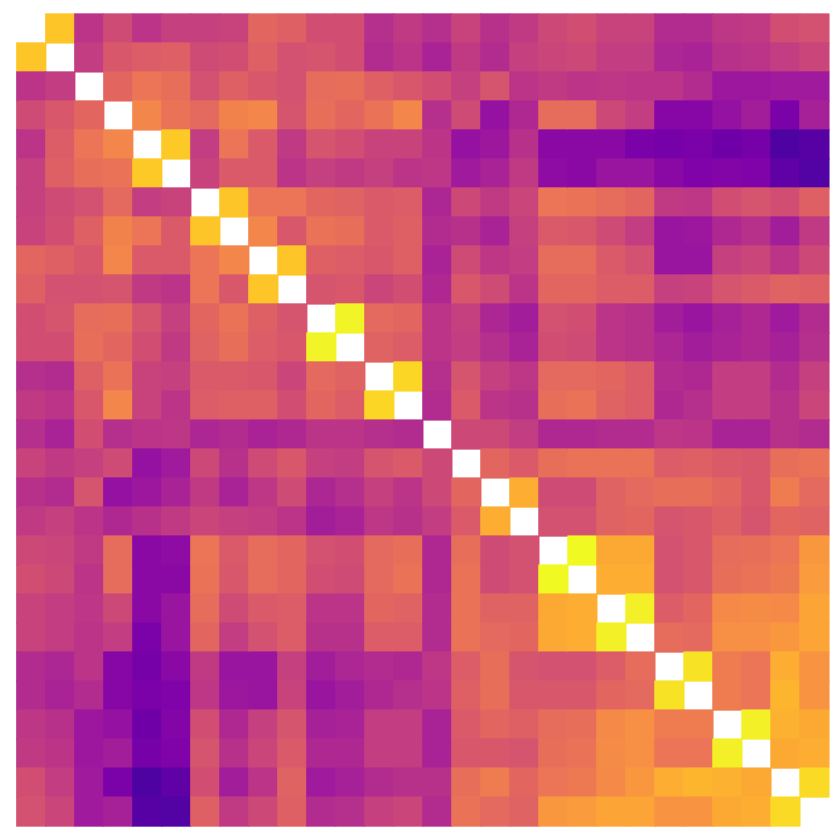

In [20]:
Acapulco_volumes_only_z_cor %>%
    cor() %>%
    corrplot(method = 'color', 
            tl.col = "black",
            tl.cex = 0.7,
            tl.srt = 60,
            diag = F,
            tl.pos = "n",
            is.corr = T,
            order = "hclust", 
            hclust.method = "ward.D",
            col = plasma(100),
            cl.pos = "n")

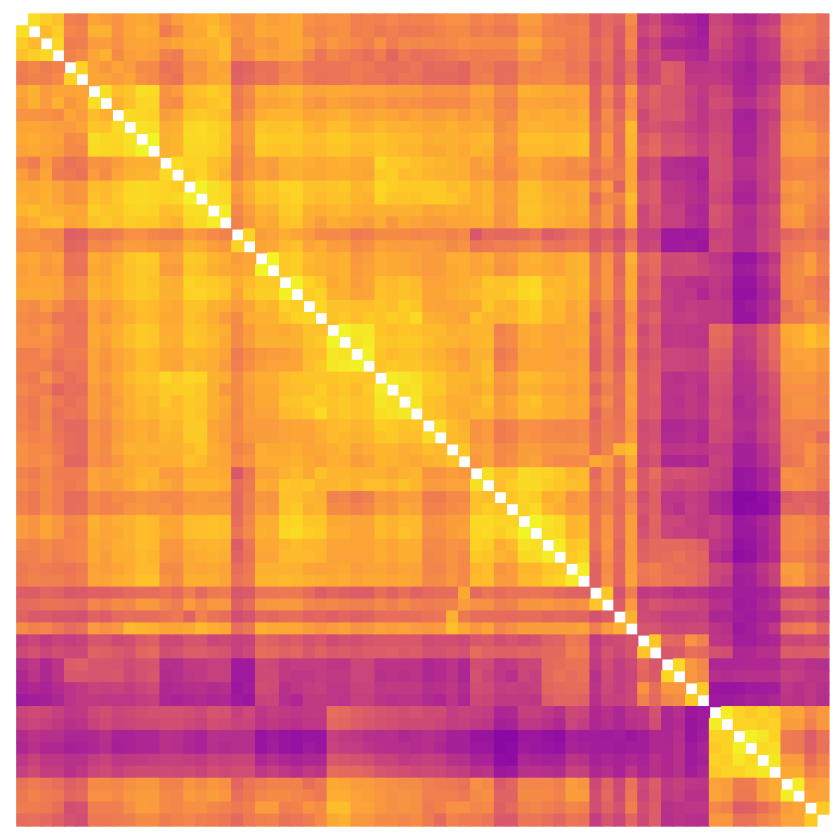

In [21]:
DK_volumes_only_z_cor %>%
    cor() %>%
    corrplot(method = 'color', 
            tl.col = "black",
            tl.cex = 0.7,
            tl.srt = 60,
            diag = F,
            tl.pos = "n",
            is.corr = T,
            order = "hclust", 
            hclust.method = "ward.D",
            col = plasma(100),
            cl.pos = "n")

### SVD

In [22]:
#Rxy matrices
Acapulco_DK_Rxy <- cor(Acapulco_volumes_only_z, DK_volumes_only_z, method = "spearman")

#Omega matrices
Acapulco_DK_omega <- t(solve(chol(Acapulco_volumes_only_z_cor))) %*% Acapulco_DK_Rxy %*% solve(chol(DK_volumes_only_z_cor))

##getting the variance explained of each singular value
Acapulco_DK_PLS_svd_scaled <- svd(Acapulco_DK_Rxy)

Acapulco_DK_PLS_variance <- Acapulco_DK_PLS_svd_scaled$d^2/sum(Acapulco_DK_PLS_svd_scaled$d^2)

In [23]:
#Standardizing the V singular values by the singular values
Acapulco_DK_S_diag_PLS <- as.data.frame(diag(Acapulco_DK_PLS_svd_scaled$d))
Acapulco_DK_S_diag_PLS <- as.matrix(Acapulco_DK_S_diag_PLS)
Acapulco_DK_V_S_PLS <- Acapulco_DK_PLS_svd_scaled$v %*% Acapulco_DK_S_diag_PLS

#projecting the standardized V singular values by the residualized and normalized brain matrix 
Acapulco_DK_V_Ymat_PLS <- DK_volumes_only_z %*% Acapulco_DK_V_S_PLS
Acapulco_DK_V_Ymat_PLS <- as.data.frame(Acapulco_DK_V_Ymat_PLS)

#Standardizing the U singular values by the singular values
Acapulco_DK_U_S_PLS <- Acapulco_DK_PLS_svd_scaled$u %*% Acapulco_DK_S_diag_PLS

#projecting the standardized U singular values by the residualized and normalized behaviour matrix
Acapulco_DK_U_Xmat_PLS <- Acapulco_volumes_only_z %*% Acapulco_DK_U_S_PLS
Acapulco_DK_U_Xmat_PLS <- as.data.frame(Acapulco_DK_U_Xmat_PLS)

In [24]:
Acapulco_DK_latentScores_list_PLS <- lapply(1:28, function(i) tibble(U = Acapulco_DK_U_Xmat_PLS[, i], V = Acapulco_DK_V_Ymat_PLS[, i])) %>% 
    set_names(paste0("LV_", 1:28))

## Running PLS

### Permutation

In [25]:
set.seed(42)
PLS_permutation <- function(X, Y, numboot) {

    ##creating data container that we will use to input the singular values later on
    sum_of_squares1 <- vector("list", numboot)
    sum_of_squares2 <- vector("list", numboot)
    sum_of_squares3 <- vector("list", numboot)
    sum_of_squares4 <- vector("list", numboot)
    sum_of_squares5 <- vector("list", numboot)
    sum_of_squares6 <- vector("list", numboot)
    sum_of_squares7 <- vector("list", numboot)
    sum_of_squares8 <- vector("list", numboot)
    sum_of_squares9 <- vector("list", numboot)
    sum_of_squares10 <- vector("list", numboot)
    sum_of_squares11 <- vector("list", numboot)
    sum_of_squares12 <- vector("list", numboot)
    sum_of_squares13 <- vector("list", numboot)
    sum_of_squares14 <- vector("list", numboot)
    sum_of_squares15 <- vector("list", numboot)
    sum_of_squares16 <- vector("list", numboot)
    sum_of_squares17 <- vector("list", numboot)
    sum_of_squares18 <- vector("list", numboot)
    sum_of_squares19 <- vector("list", numboot)
    sum_of_squares20 <- vector("list", numboot)
    sum_of_squares21 <- vector("list", numboot)
    sum_of_squares22 <- vector("list", numboot)
    sum_of_squares23 <- vector("list", numboot)
    sum_of_squares24 <- vector("list", numboot)
    sum_of_squares25 <- vector("list", numboot)
    sum_of_squares26 <- vector("list", numboot)
    sum_of_squares27 <- vector("list", numboot)
    sum_of_squares28 <- vector("list", numboot)

    for(i in 1:numboot) {
    
        print(i)
        resamplesX <- sample(nrow(X), replace=F)
        resamples_X <- lapply(1:numboot, function(i) X[resamplesX,])
        resamples_Y <- lapply(1:numboot, function(i) Y)

        ##getting the z-scores
        resamples_X[[i]] <- scale(resamples_X[[i]], center = TRUE, scale = TRUE)
        resamples_Y[[i]] <- scale(resamples_Y[[i]], center = TRUE, scale = TRUE)

        ###preparing the Spearman correlation
        resamples_X_cor <- cor(resamples_X[[i]], method = "spearman")
        resamples_Y_cor <- cor(resamples_Y[[i]], method = "spearman")

        #Rxy matrices
        resamples_Rxy <- cor(resamples_X[[i]], resamples_Y[[i]], method = "spearman")

        ##getting the variance explained of each singular value
        resamples_PLS_svd_scaled <- svd(resamples_Rxy)

        ##getting the singular values
        resamples_singular_values <- as.data.frame(resamples_PLS_svd_scaled$d)
        
        ##getting the sum of square singular values 
        resamples_sing_values_squared <- as.data.frame(apply(resamples_singular_values, 1, function(x) x^2))
        resamples_sing_values_squared_summed1 <- sum(resamples_sing_values_squared)

        resamples_singular_values2_28 <- as.data.frame(resamples_singular_values[-c(1),])
        resamples_sing_values_squared2_28 <- as.data.frame(apply(resamples_singular_values2_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed2 <- sum(resamples_sing_values_squared2_28)

        resamples_singular_values3_28 <- as.data.frame(resamples_singular_values[-c(1,2),])
        resamples_sing_values_squared3_28 <- as.data.frame(apply(resamples_singular_values3_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed3 <- sum(resamples_sing_values_squared3_28)

        resamples_singular_values4_28 <- as.data.frame(resamples_singular_values[-c(1,2,3),])
        resamples_sing_values_squared4_28 <- as.data.frame(apply(resamples_singular_values4_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed4 <- sum(resamples_sing_values_squared4_28)

        resamples_singular_values5_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4),])
        resamples_sing_values_squared5_28 <- as.data.frame(apply(resamples_singular_values5_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed5 <- sum(resamples_sing_values_squared5_28)

        resamples_singular_values6_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5),])
        resamples_sing_values_squared6_28 <- as.data.frame(apply(resamples_singular_values6_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed6 <- sum(resamples_sing_values_squared6_28)

        resamples_singular_values7_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6),])
        resamples_sing_values_squared7_28 <- as.data.frame(apply(resamples_singular_values7_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed7 <- sum(resamples_sing_values_squared7_28)
        
        resamples_singular_values8_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7),])
        resamples_sing_values_squared8_28 <- as.data.frame(apply(resamples_singular_values8_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed8 <- sum(resamples_sing_values_squared8_28)

        resamples_singular_values9_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8),])
        resamples_sing_values_squared9_28 <- as.data.frame(apply(resamples_singular_values9_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed9 <- sum(resamples_sing_values_squared9_28)

        resamples_singular_values10_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9),])
        resamples_sing_values_squared10_28 <- as.data.frame(apply(resamples_singular_values10_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed10 <- sum(resamples_sing_values_squared10_28)

        resamples_singular_values11_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10),])
        resamples_sing_values_squared11_28 <- as.data.frame(apply(resamples_singular_values11_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed11 <- sum(resamples_sing_values_squared11_28)

        resamples_singular_values12_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11),])
        resamples_sing_values_squared12_28 <- as.data.frame(apply(resamples_singular_values12_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed12 <- sum(resamples_sing_values_squared12_28)

        resamples_singular_values13_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12),])
        resamples_sing_values_squared13_28 <- as.data.frame(apply(resamples_singular_values13_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed13 <- sum(resamples_sing_values_squared13_28)

        resamples_singular_values14_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13),])
        resamples_sing_values_squared14_28 <- as.data.frame(apply(resamples_singular_values14_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed14 <- sum(resamples_sing_values_squared14_28)

        resamples_singular_values15_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14),])
        resamples_sing_values_squared15_28 <- as.data.frame(apply(resamples_singular_values15_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed15 <- sum(resamples_sing_values_squared15_28)

        resamples_singular_values16_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15),])
        resamples_sing_values_squared16_28 <- as.data.frame(apply(resamples_singular_values16_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed16 <- sum(resamples_sing_values_squared16_28)

        resamples_singular_values17_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16),])
        resamples_sing_values_squared17_28 <- as.data.frame(apply(resamples_singular_values17_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed17 <- sum(resamples_sing_values_squared17_28)

        resamples_singular_values18_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17),])
        resamples_sing_values_squared18_28 <- as.data.frame(apply(resamples_singular_values18_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed18 <- sum(resamples_sing_values_squared18_28)

        resamples_singular_values19_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18),])
        resamples_sing_values_squared19_28 <- as.data.frame(apply(resamples_singular_values19_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed19 <- sum(resamples_sing_values_squared19_28)

        resamples_singular_values20_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19),])
        resamples_sing_values_squared20_28 <- as.data.frame(apply(resamples_singular_values20_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed20 <- sum(resamples_sing_values_squared20_28)

        resamples_singular_values21_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20),])
        resamples_sing_values_squared21_28 <- as.data.frame(apply(resamples_singular_values21_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed21 <- sum(resamples_sing_values_squared21_28)

        resamples_singular_values22_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21),])
        resamples_sing_values_squared22_28 <- as.data.frame(apply(resamples_singular_values22_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed22 <- sum(resamples_sing_values_squared22_28)

        resamples_singular_values23_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22),])
        resamples_sing_values_squared23_28 <- as.data.frame(apply(resamples_singular_values23_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed23 <- sum(resamples_sing_values_squared23_28)

        resamples_singular_values24_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23),])
        resamples_sing_values_squared24_28 <- as.data.frame(apply(resamples_singular_values24_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed24 <- sum(resamples_sing_values_squared24_28)

        resamples_singular_values25_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24),])
        resamples_sing_values_squared25_28 <- as.data.frame(apply(resamples_singular_values25_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed25 <- sum(resamples_sing_values_squared25_28)

        resamples_singular_values26_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25),])
        resamples_sing_values_squared26_28 <- as.data.frame(apply(resamples_singular_values26_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed26 <- sum(resamples_sing_values_squared26_28)

        resamples_singular_values27_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26),])
        resamples_sing_values_squared27_28 <- as.data.frame(apply(resamples_singular_values27_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed27 <- sum(resamples_sing_values_squared27_28)

        resamples_singular_values28_28 <- as.data.frame(resamples_singular_values[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27),])
        resamples_sing_values_squared28_28 <- as.data.frame(apply(resamples_singular_values28_28, 1, function(x) x^2))
        resamples_sing_values_squared_summed28 <- sum(resamples_sing_values_squared28_28)

        sum_of_squares1[[i]] <- resamples_sing_values_squared_summed1
        sum_of_squares2[[i]] <- resamples_sing_values_squared_summed2
        sum_of_squares3[[i]] <- resamples_sing_values_squared_summed3
        sum_of_squares4[[i]] <- resamples_sing_values_squared_summed4
        sum_of_squares5[[i]] <- resamples_sing_values_squared_summed5
        sum_of_squares6[[i]] <- resamples_sing_values_squared_summed6
        sum_of_squares7[[i]] <- resamples_sing_values_squared_summed7
        sum_of_squares8[[i]] <- resamples_sing_values_squared_summed8
        sum_of_squares9[[i]] <- resamples_sing_values_squared_summed9
        sum_of_squares10[[i]] <- resamples_sing_values_squared_summed10
        sum_of_squares11[[i]] <- resamples_sing_values_squared_summed11
        sum_of_squares12[[i]] <- resamples_sing_values_squared_summed12
        sum_of_squares13[[i]] <- resamples_sing_values_squared_summed13
        sum_of_squares14[[i]] <- resamples_sing_values_squared_summed14
        sum_of_squares15[[i]] <- resamples_sing_values_squared_summed15
        sum_of_squares16[[i]] <- resamples_sing_values_squared_summed16
        sum_of_squares17[[i]] <- resamples_sing_values_squared_summed17
        sum_of_squares18[[i]] <- resamples_sing_values_squared_summed18
        sum_of_squares19[[i]] <- resamples_sing_values_squared_summed19
        sum_of_squares20[[i]] <- resamples_sing_values_squared_summed20
        sum_of_squares21[[i]] <- resamples_sing_values_squared_summed21
        sum_of_squares22[[i]] <- resamples_sing_values_squared_summed22
        sum_of_squares23[[i]] <- resamples_sing_values_squared_summed23
        sum_of_squares24[[i]] <- resamples_sing_values_squared_summed24
        sum_of_squares25[[i]] <- resamples_sing_values_squared_summed25
        sum_of_squares26[[i]] <- resamples_sing_values_squared_summed26
        sum_of_squares27[[i]] <- resamples_sing_values_squared_summed27
        sum_of_squares28[[i]] <- resamples_sing_values_squared_summed28
}

    return(list("sum_of_squares1" = sum_of_squares1, "sum_of_squares2" = sum_of_squares2, "sum_of_squares3" = sum_of_squares3, 
        "sum_of_squares4" = sum_of_squares4, "sum_of_squares5" = sum_of_squares5, "sum_of_squares6" = sum_of_squares6, 
        "sum_of_squares7" = sum_of_squares7, "sum_of_squares8" = sum_of_squares8, "sum_of_squares9" = sum_of_squares9, 
        "sum_of_squares10" = sum_of_squares10, "sum_of_squares11" = sum_of_squares11, "sum_of_squares12" = sum_of_squares12, 
        "sum_of_squares13" = sum_of_squares13, "sum_of_squares14" = sum_of_squares14, 
        "sum_of_squares15" = sum_of_squares15, "sum_of_squares16" = sum_of_squares16, 
        "sum_of_squares17" = sum_of_squares17, "sum_of_squares18" = sum_of_squares18, 
        "sum_of_squares19" = sum_of_squares19, "sum_of_squares20" = sum_of_squares20, 
        "sum_of_squares21" = sum_of_squares21, "sum_of_squares22" = sum_of_squares22, 
        "sum_of_squares23" = sum_of_squares23, "sum_of_squares24" = sum_of_squares24, 
        "sum_of_squares25" = sum_of_squares25, "sum_of_squares26" = sum_of_squares26, 
        "sum_of_squares27" = sum_of_squares27, "sum_of_squares28" = sum_of_squares28))
}

In [26]:
cores=detectCores()
cl <- makeCluster(cores[1]-1)

registerDoParallel(cl)

if (!file.exists("Data/RData/PLS_permutation_Acapulco.RData")) {
    PLS_permutation_output <- foreach(i=1:split_tt) %dopar% {
        PLS_permutation(Acapulco_volumes_only, DK_volumes_only, split_tt)
    }
    save(PLS_permutation_output, file = "Data/RData/PLS_permutation_Acapulco.RData")
} else {
    load("Data/RData/PLS_permutation_Acapulco.RData")
}

stopCluster(cl)

In [27]:
#### getting the sum of squares for each LV
Acapulco_DK_singVal <- as.data.frame(Acapulco_DK_PLS_svd_scaled$d)

####1 THROUGH 28
Acapulco_DK_singVal_squared <- as.data.frame(apply(Acapulco_DK_singVal, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed1 <- sum(Acapulco_DK_singVal_squared)

Acapulco_DK_singVal2_28 <- as.data.frame(Acapulco_DK_singVal[-c(1),])
Acapulco_DK_singVal_squared2_28 <- as.data.frame(apply(Acapulco_DK_singVal2_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed2 <- sum(Acapulco_DK_singVal_squared2_28)

Acapulco_DK_singVal3_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2),])
Acapulco_DK_singVal_squared3_28 <- as.data.frame(apply(Acapulco_DK_singVal3_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed3 <- sum(Acapulco_DK_singVal_squared3_28)

Acapulco_DK_singVal4_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3),])
Acapulco_DK_singVal_squared4_28 <- as.data.frame(apply(Acapulco_DK_singVal4_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed4 <- sum(Acapulco_DK_singVal_squared4_28)

Acapulco_DK_singVal5_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4),])
Acapulco_DK_singVal_squared5_28 <- as.data.frame(apply(Acapulco_DK_singVal5_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed5 <- sum(Acapulco_DK_singVal_squared5_28)

Acapulco_DK_singVal6_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5),])
Acapulco_DK_singVal_squared6_28 <- as.data.frame(apply(Acapulco_DK_singVal6_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed6 <- sum(Acapulco_DK_singVal_squared6_28)

Acapulco_DK_singVal7_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6),])
Acapulco_DK_singVal_squared7_28 <- as.data.frame(apply(Acapulco_DK_singVal7_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed7 <- sum(Acapulco_DK_singVal_squared7_28)

Acapulco_DK_singVal8_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7),])
Acapulco_DK_singVal_squared8_28 <- as.data.frame(apply(Acapulco_DK_singVal8_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed8 <- sum(Acapulco_DK_singVal_squared8_28)

Acapulco_DK_singVal9_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8),])
Acapulco_DK_singVal_squared9_28 <- as.data.frame(apply(Acapulco_DK_singVal9_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed9 <- sum(Acapulco_DK_singVal_squared9_28)

Acapulco_DK_singVal10_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9),])
Acapulco_DK_singVal_squared10_28 <- as.data.frame(apply(Acapulco_DK_singVal10_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed10 <- sum(Acapulco_DK_singVal_squared10_28)

Acapulco_DK_singVal11_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10),])
Acapulco_DK_singVal_squared11_28 <- as.data.frame(apply(Acapulco_DK_singVal11_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed11 <- sum(Acapulco_DK_singVal_squared11_28)

Acapulco_DK_singVal12_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11),])
Acapulco_DK_singVal_squared12_28 <- as.data.frame(apply(Acapulco_DK_singVal12_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed12 <- sum(Acapulco_DK_singVal_squared12_28)

Acapulco_DK_singVal13_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12),])
Acapulco_DK_singVal_squared13_28 <- as.data.frame(apply(Acapulco_DK_singVal13_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed13 <- sum(Acapulco_DK_singVal_squared13_28)

Acapulco_DK_singVal14_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13),])
Acapulco_DK_singVal_squared14_28 <- as.data.frame(apply(Acapulco_DK_singVal14_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed14 <- sum(Acapulco_DK_singVal_squared14_28)

Acapulco_DK_singVal15_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14),])
Acapulco_DK_singVal_squared15_28 <- as.data.frame(apply(Acapulco_DK_singVal15_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed15 <- sum(Acapulco_DK_singVal_squared15_28)

Acapulco_DK_singVal16_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15),])
Acapulco_DK_singVal_squared16_28 <- as.data.frame(apply(Acapulco_DK_singVal16_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed16 <- sum(Acapulco_DK_singVal_squared16_28)

Acapulco_DK_singVal17_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16),])
Acapulco_DK_singVal_squared17_28 <- as.data.frame(apply(Acapulco_DK_singVal17_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed17 <- sum(Acapulco_DK_singVal_squared17_28)

Acapulco_DK_singVal18_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17),])
Acapulco_DK_singVal_squared18_28 <- as.data.frame(apply(Acapulco_DK_singVal18_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed18 <- sum(Acapulco_DK_singVal_squared18_28)

Acapulco_DK_singVal19_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18),])
Acapulco_DK_singVal_squared19_28 <- as.data.frame(apply(Acapulco_DK_singVal19_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed19 <- sum(Acapulco_DK_singVal_squared19_28)

Acapulco_DK_singVal20_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19),])
Acapulco_DK_singVal_squared20_28 <- as.data.frame(apply(Acapulco_DK_singVal20_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed20 <- sum(Acapulco_DK_singVal_squared20_28)

Acapulco_DK_singVal21_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20),])
Acapulco_DK_singVal_squared21_28 <- as.data.frame(apply(Acapulco_DK_singVal21_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed21 <- sum(Acapulco_DK_singVal_squared21_28)

Acapulco_DK_singVal22_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21),])
Acapulco_DK_singVal_squared22_28 <- as.data.frame(apply(Acapulco_DK_singVal22_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed22 <- sum(Acapulco_DK_singVal_squared22_28)

Acapulco_DK_singVal23_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22),])
Acapulco_DK_singVal_squared23_28 <- as.data.frame(apply(Acapulco_DK_singVal23_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed23 <- sum(Acapulco_DK_singVal_squared23_28)

Acapulco_DK_singVal24_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23),])
Acapulco_DK_singVal_squared24_28 <- as.data.frame(apply(Acapulco_DK_singVal24_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed24 <- sum(Acapulco_DK_singVal_squared24_28)

Acapulco_DK_singVal25_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24),])
Acapulco_DK_singVal_squared25_28 <- as.data.frame(apply(Acapulco_DK_singVal25_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed25 <- sum(Acapulco_DK_singVal_squared25_28)

Acapulco_DK_singVal26_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25),])
Acapulco_DK_singVal_squared26_28 <- as.data.frame(apply(Acapulco_DK_singVal26_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed26 <- sum(Acapulco_DK_singVal_squared26_28)

Acapulco_DK_singVal27_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26),])
Acapulco_DK_singVal_squared27_28 <- as.data.frame(apply(Acapulco_DK_singVal27_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed27 <- sum(Acapulco_DK_singVal_squared27_28)

Acapulco_DK_singVal28_28 <- as.data.frame(Acapulco_DK_singVal[-c(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27),])
Acapulco_DK_singVal_squared28_28 <- as.data.frame(apply(Acapulco_DK_singVal28_28, 1, function(x) x^2))
Acapulco_DK_singVal_squared_summed28 <- sum(Acapulco_DK_singVal_squared28_28)

In [28]:
#### Creating data frames of the sum of square singular values 
Acapulco_DK_singVal1_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares1))
Acapulco_DK_singVal1_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal1_permutation_results))

Acapulco_DK_singVal2_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares2))
Acapulco_DK_singVal2_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal2_permutation_results))

Acapulco_DK_singVal3_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares3))
Acapulco_DK_singVal3_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal3_permutation_results))

Acapulco_DK_singVal4_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares4))
Acapulco_DK_singVal4_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal4_permutation_results))

Acapulco_DK_singVal5_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares5))
Acapulco_DK_singVal5_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal5_permutation_results))

Acapulco_DK_singVal6_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares6))
Acapulco_DK_singVal6_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal6_permutation_results))

Acapulco_DK_singVal7_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares7))
Acapulco_DK_singVal7_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal7_permutation_results))

Acapulco_DK_singVal8_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares8))
Acapulco_DK_singVal8_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal8_permutation_results))

Acapulco_DK_singVal9_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares9))
Acapulco_DK_singVal9_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal9_permutation_results))

Acapulco_DK_singVal10_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares10))
Acapulco_DK_singVal10_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal10_permutation_results))

Acapulco_DK_singVal11_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares11))
Acapulco_DK_singVal11_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal11_permutation_results))

Acapulco_DK_singVal12_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares12))
Acapulco_DK_singVal12_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal12_permutation_results))

Acapulco_DK_singVal13_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares13))
Acapulco_DK_singVal13_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal13_permutation_results))

Acapulco_DK_singVal14_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares14))
Acapulco_DK_singVal14_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal14_permutation_results))

Acapulco_DK_singVal15_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares15))
Acapulco_DK_singVal15_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal15_permutation_results))

Acapulco_DK_singVal16_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares16))
Acapulco_DK_singVal16_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal16_permutation_results))

Acapulco_DK_singVal17_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares17))
Acapulco_DK_singVal17_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal17_permutation_results))

Acapulco_DK_singVal18_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares18))
Acapulco_DK_singVal18_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal18_permutation_results))

Acapulco_DK_singVal19_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares19))
Acapulco_DK_singVal19_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal19_permutation_results))

Acapulco_DK_singVal20_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares20))
Acapulco_DK_singVal20_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal20_permutation_results))

Acapulco_DK_singVal21_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares21))
Acapulco_DK_singVal21_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal21_permutation_results))

Acapulco_DK_singVal22_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares22))
Acapulco_DK_singVal22_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal22_permutation_results))

Acapulco_DK_singVal23_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares23))
Acapulco_DK_singVal23_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal23_permutation_results))

Acapulco_DK_singVal24_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares24))
Acapulco_DK_singVal24_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal24_permutation_results))

Acapulco_DK_singVal25_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares25))
Acapulco_DK_singVal25_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal25_permutation_results))

Acapulco_DK_singVal26_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares26))
Acapulco_DK_singVal26_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal26_permutation_results))

Acapulco_DK_singVal27_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares27))
Acapulco_DK_singVal27_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal27_permutation_results))

Acapulco_DK_singVal28_permutation_results <- sapply(1:100, function(i) unlist(PLS_permutation_output[[i]]$sum_of_squares28))
Acapulco_DK_singVal28_permutation_results <- as.data.frame(as.vector(Acapulco_DK_singVal28_permutation_results))

In [29]:
#### getting the p-value 
Acapulco_DK_pval_singVal1 <- filter(Acapulco_DK_singVal1_permutation_results, Acapulco_DK_singVal1_permutation_results >= Acapulco_DK_singVal_squared_summed1)
Acapulco_DK_pval_singVal2 <- filter(Acapulco_DK_singVal2_permutation_results, Acapulco_DK_singVal2_permutation_results >= Acapulco_DK_singVal_squared_summed2)
Acapulco_DK_pval_singVal3 <- filter(Acapulco_DK_singVal3_permutation_results, Acapulco_DK_singVal3_permutation_results >= Acapulco_DK_singVal_squared_summed3)
Acapulco_DK_pval_singVal4 <- filter(Acapulco_DK_singVal4_permutation_results, Acapulco_DK_singVal4_permutation_results >= Acapulco_DK_singVal_squared_summed4)
Acapulco_DK_pval_singVal5 <- filter(Acapulco_DK_singVal5_permutation_results, Acapulco_DK_singVal5_permutation_results >= Acapulco_DK_singVal_squared_summed5)
Acapulco_DK_pval_singVal6 <- filter(Acapulco_DK_singVal6_permutation_results, Acapulco_DK_singVal6_permutation_results >= Acapulco_DK_singVal_squared_summed6)
Acapulco_DK_pval_singVal7 <- filter(Acapulco_DK_singVal7_permutation_results, Acapulco_DK_singVal7_permutation_results >= Acapulco_DK_singVal_squared_summed7)
Acapulco_DK_pval_singVal8 <- filter(Acapulco_DK_singVal8_permutation_results, Acapulco_DK_singVal8_permutation_results >= Acapulco_DK_singVal_squared_summed8)
Acapulco_DK_pval_singVal9 <- filter(Acapulco_DK_singVal9_permutation_results, Acapulco_DK_singVal9_permutation_results >= Acapulco_DK_singVal_squared_summed9)
Acapulco_DK_pval_singVal10 <- filter(Acapulco_DK_singVal10_permutation_results, Acapulco_DK_singVal10_permutation_results >= Acapulco_DK_singVal_squared_summed10)
Acapulco_DK_pval_singVal11 <- filter(Acapulco_DK_singVal11_permutation_results, Acapulco_DK_singVal11_permutation_results >= Acapulco_DK_singVal_squared_summed11)
Acapulco_DK_pval_singVal12 <- filter(Acapulco_DK_singVal12_permutation_results, Acapulco_DK_singVal12_permutation_results >= Acapulco_DK_singVal_squared_summed12)
Acapulco_DK_pval_singVal13 <- filter(Acapulco_DK_singVal13_permutation_results, Acapulco_DK_singVal13_permutation_results >= Acapulco_DK_singVal_squared_summed13)
Acapulco_DK_pval_singVal14 <- filter(Acapulco_DK_singVal14_permutation_results, Acapulco_DK_singVal14_permutation_results >= Acapulco_DK_singVal_squared_summed14)
Acapulco_DK_pval_singVal15 <- filter(Acapulco_DK_singVal15_permutation_results, Acapulco_DK_singVal15_permutation_results >= Acapulco_DK_singVal_squared_summed15)
Acapulco_DK_pval_singVal16 <- filter(Acapulco_DK_singVal16_permutation_results, Acapulco_DK_singVal16_permutation_results >= Acapulco_DK_singVal_squared_summed16)
Acapulco_DK_pval_singVal17 <- filter(Acapulco_DK_singVal17_permutation_results, Acapulco_DK_singVal17_permutation_results >= Acapulco_DK_singVal_squared_summed17)
Acapulco_DK_pval_singVal18 <- filter(Acapulco_DK_singVal18_permutation_results, Acapulco_DK_singVal18_permutation_results >= Acapulco_DK_singVal_squared_summed18)
Acapulco_DK_pval_singVal19 <- filter(Acapulco_DK_singVal19_permutation_results, Acapulco_DK_singVal19_permutation_results >= Acapulco_DK_singVal_squared_summed19)
Acapulco_DK_pval_singVal20 <- filter(Acapulco_DK_singVal20_permutation_results, Acapulco_DK_singVal20_permutation_results >= Acapulco_DK_singVal_squared_summed20)
Acapulco_DK_pval_singVal21 <- filter(Acapulco_DK_singVal21_permutation_results, Acapulco_DK_singVal21_permutation_results >= Acapulco_DK_singVal_squared_summed21)
Acapulco_DK_pval_singVal22 <- filter(Acapulco_DK_singVal22_permutation_results, Acapulco_DK_singVal22_permutation_results >= Acapulco_DK_singVal_squared_summed22)
Acapulco_DK_pval_singVal23 <- filter(Acapulco_DK_singVal23_permutation_results, Acapulco_DK_singVal23_permutation_results >= Acapulco_DK_singVal_squared_summed23)
Acapulco_DK_pval_singVal24 <- filter(Acapulco_DK_singVal24_permutation_results, Acapulco_DK_singVal24_permutation_results >= Acapulco_DK_singVal_squared_summed24)
Acapulco_DK_pval_singVal25 <- filter(Acapulco_DK_singVal25_permutation_results, Acapulco_DK_singVal25_permutation_results >= Acapulco_DK_singVal_squared_summed25)
Acapulco_DK_pval_singVal26 <- filter(Acapulco_DK_singVal26_permutation_results, Acapulco_DK_singVal26_permutation_results >= Acapulco_DK_singVal_squared_summed26)
Acapulco_DK_pval_singVal27 <- filter(Acapulco_DK_singVal27_permutation_results, Acapulco_DK_singVal27_permutation_results >= Acapulco_DK_singVal_squared_summed27)
Acapulco_DK_pval_singVal28 <- filter(Acapulco_DK_singVal28_permutation_results, Acapulco_DK_singVal28_permutation_results >= Acapulco_DK_singVal_squared_summed28)

### Bootstrap

In [30]:
bootstrap_resampling_PLS_SingularVectors <- function(X, Y, numboot, nsub) {

    numboot <- numboot 
    ##creating a data container to hold all the matrices
    U_mat <- vector("list", numboot)
    V_mat <- vector("list", numboot)
    
    Xrow <- nrow(X)
    Yrow <- nrow(Y)
    y <- nsub
    
    for(i in 1:numboot) {
        print(i) ##permutation number
        resamples_X <- lapply(1:numboot, function(idx) X[sample(Xrow,y, replace = T),])
        resamples_Y <- lapply(1:numboot, function(idx) Y[sample(Xrow,y, replace = T),])
        
        ##getting the z-scores (split half 1)
        resamples_X[[i]] <- scale(resamples_X[[i]], center = TRUE, scale = TRUE)
        resamples_Y[[i]] <- scale(resamples_Y[[i]], center = TRUE, scale = TRUE)

        ###preparing the Spearman correlation
        resamples_X_cor <- cor(resamples_X[[i]], method = "spearman")
        resamples_Y_cor <- cor(resamples_Y[[i]], method = "spearman")

        #Rxy matrices
        resamples_Rxy <- cor(resamples_X[[i]], resamples_Y[[i]], method = "spearman")

        ##getting the variance explained of each singular value
        resamples_PLS_svd_scaled <- svd(resamples_Rxy)
        
        ##getting the singular vector matrices
        U_matrix <- resamples_PLS_svd_scaled$u
        V_matrix <- resamples_PLS_svd_scaled$v
        
        U_mat[[i]] <- U_matrix
        V_mat[[i]] <- V_matrix
    }
    
    ##this returns a data container with a series of variables which each have a list of matrices that can be extracted
    return(list("U_mat" = U_mat, "V_mat" = V_mat))
}

In [31]:
cores=detectCores()
cl <- makeCluster(cores[1]-1)

registerDoParallel(cl)

if (!file.exists("Data/RData/PLS_bootstrap_singvectors_Acapulco.RData")) {
    bootstrap_PLS_singvectors <- bootstrap_resampling_PLS_SingularVectors(Acapulco_volumes_only, DK_volumes_only, boot_perm, Acapulco_volumes_only %>% nrow())
    save(bootstrap_PLS_singvectors, file = "Data/RData/PLS_bootstrap_singvectors_Acapulco.RData")
} else {
    load("Data/RData/PLS_bootstrap_singvectors_Acapulco.RData")
}

stopCluster(cl)

### Split-Half

In [32]:
set.seed(42)
PLS_splithalf <- function(X, Y, numboot){
    
    X <- X ##X matrix
    Y <- Y ##Y matrix
    numboot <- numboot # number of permutations 

    # Initialize empty list of length numboot for the different outputs we want
    SingVectors_V1 <- vector("list", numboot)
    SingVectors_U1 <- vector("list", numboot)
    SingVectors_V2 <- vector("list", numboot)
    SingVectors_U2 <- vector("list", numboot)
    SingVectors_V3 <- vector("list", numboot)
    SingVectors_U3 <- vector("list", numboot)
    SingVectors_V4 <- vector("list", numboot)
    SingVectors_U4 <- vector("list", numboot)
    SingVectors_V5 <- vector("list", numboot)
    SingVectors_U5 <- vector("list", numboot)
    SingVectors_V6 <- vector("list", numboot)
    SingVectors_U6 <- vector("list", numboot)
    SingVectors_V7 <- vector("list", numboot)
    SingVectors_U7 <- vector("list", numboot)
    SingVectors_V8 <- vector("list", numboot)
    SingVectors_U8 <- vector("list", numboot)
    SingVectors_V9 <- vector("list", numboot)
    SingVectors_U9 <- vector("list", numboot)
    SingVectors_V10 <- vector("list", numboot)
    SingVectors_U10 <- vector("list", numboot)
    SingVectors_V11 <- vector("list", numboot)
    SingVectors_U11 <- vector("list", numboot)
    SingVectors_U12 <- vector("list", numboot)
    SingVectors_V12 <- vector("list", numboot)
    SingVectors_V13 <- vector("list", numboot)
    SingVectors_U13 <- vector("list", numboot)
    SingVectors_V14 <- vector("list", numboot)
    SingVectors_U14 <- vector("list", numboot)
    SingVectors_V15 <- vector("list", numboot)
    SingVectors_U15 <- vector("list", numboot)
    SingVectors_V16 <- vector("list", numboot)
    SingVectors_U16 <- vector("list", numboot)
    SingVectors_V17 <- vector("list", numboot)
    SingVectors_U17 <- vector("list", numboot)
    SingVectors_V18 <- vector("list", numboot)
    SingVectors_U18 <- vector("list", numboot)
    SingVectors_V19 <- vector("list", numboot)
    SingVectors_U19 <- vector("list", numboot)
    SingVectors_V20 <- vector("list", numboot)
    SingVectors_U20 <- vector("list", numboot)
    SingVectors_V21 <- vector("list", numboot)
    SingVectors_U21 <- vector("list", numboot)
    SingVectors_V22 <- vector("list", numboot)
    SingVectors_U22 <- vector("list", numboot)
    SingVectors_V23 <- vector("list", numboot)
    SingVectors_U23 <- vector("list", numboot)
    SingVectors_V24 <- vector("list", numboot)
    SingVectors_U24 <- vector("list", numboot)
    SingVectors_V25 <- vector("list", numboot)
    SingVectors_U25 <- vector("list", numboot)
    SingVectors_V26 <- vector("list", numboot)
    SingVectors_U26 <- vector("list", numboot)
    SingVectors_V27 <- vector("list", numboot)
    SingVectors_U27 <- vector("list", numboot)
    SingVectors_V28 <- vector("list", numboot)
    SingVectors_U28 <- vector("list", numboot)

    
    for(i in 1:numboot) {
        print(i) # permutation number
        
        split_half1 <- sort(sample(nrow(X), floor(nrow(X)/2), replace=F))
        split_half2 <- setdiff(1:nrow(X),split_half1)
        
        ##splitting the X matrices based on the indices of the previous steps
        new_sampleX1 <- lapply(1:numboot, function(i) X[split_half1,])
        new_sampleX2 <- lapply(1:numboot, function(i) X[split_half2,]) 
        
        ##splitting the Y matrices based on the indices of the previous steps (this ensures that the same rows are indexed in the X and Y matrices)
        new_sampleY1 <- lapply(1:numboot, function(i) Y[split_half1,])
        new_sampleY2 <- lapply(1:numboot, function(i) Y[split_half2,]) 
        
        ##getting the z-scores (split half 1)
        new_sampleX1[[i]] <- scale(new_sampleX1[[i]], center = TRUE, scale = TRUE)
        new_sampleY1[[i]] <- scale(new_sampleY1[[i]], center = TRUE, scale = TRUE)
        
        ##getting the z-scores (split half 1)
        new_sampleX2[[i]] <- scale(new_sampleX2[[i]], center = TRUE, scale = TRUE)
        new_sampleY2[[i]] <- scale(new_sampleY2[[i]], center = TRUE, scale = TRUE)
        
        ##getting the correlation and cross-correlation matrices for each split half 
        Rxy_1 <- cor(new_sampleX1[[i]], new_sampleY1[[i]], method = "spearman")
        Rxy_2 <- cor(new_sampleX2[[i]], new_sampleY2[[i]], method = "spearman")
        
        ##performing the decomposition 
        svd1 <- svd(Rxy_1)
        svd2 <- svd(Rxy_2)
        
        ##getting the correlation matrices of the u and v decomposition 
        LV_X_Corr <- cor(svd1$u, svd2$u) 
        LV_Y_Corr <- cor(svd1$v, svd2$v)
        
        ####getting the diagonal and absolute value of the correlation matrices (the sign is not relevant here)
        diagonal_LV_Y_Corr <- as.data.frame(diag(abs(LV_Y_Corr)))
        diagonal_LV_X_Corr <- as.data.frame(diag(abs(LV_X_Corr)))

        ### extracting the first singular vector from each iteration in a single variable 
        LV1_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[1,])
        LV1_corr_elements_X <- rbind(diagonal_LV_X_Corr[1,])

        LV2_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[2,])
        LV2_corr_elements_X <- rbind(diagonal_LV_X_Corr[2,])

        LV3_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[3,])
        LV3_corr_elements_X <- rbind(diagonal_LV_X_Corr[3,])

        LV4_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[4,])
        LV4_corr_elements_X <- rbind(diagonal_LV_X_Corr[4,])

        LV5_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[5,])
        LV5_corr_elements_X <- rbind(diagonal_LV_X_Corr[5,])

        LV6_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[6,])
        LV6_corr_elements_X <- rbind(diagonal_LV_X_Corr[6,])
        
        LV7_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[7,])
        LV7_corr_elements_X <- rbind(diagonal_LV_X_Corr[7,])
        
        LV8_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[8,])
        LV8_corr_elements_X <- rbind(diagonal_LV_X_Corr[8,])
        
        LV9_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[9,])
        LV9_corr_elements_X <- rbind(diagonal_LV_X_Corr[9,])
        
        LV10_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[10,])
        LV10_corr_elements_X <- rbind(diagonal_LV_X_Corr[10,])
        
        LV11_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[11,])
        LV11_corr_elements_X <- rbind(diagonal_LV_X_Corr[11,])
        
        LV12_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[12,])
        LV12_corr_elements_X <- rbind(diagonal_LV_X_Corr[12,])
        
        LV13_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[13,])
        LV13_corr_elements_X <- rbind(diagonal_LV_X_Corr[13,])
        
        LV14_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[14,])
        LV14_corr_elements_X <- rbind(diagonal_LV_X_Corr[14,])
        
        LV15_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[15,])
        LV15_corr_elements_X <- rbind(diagonal_LV_X_Corr[15,])
        
        LV16_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[16,])
        LV16_corr_elements_X <- rbind(diagonal_LV_X_Corr[16,])
        
        LV17_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[17,])
        LV17_corr_elements_X <- rbind(diagonal_LV_X_Corr[17,])
        
        LV18_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[18,])
        LV18_corr_elements_X <- rbind(diagonal_LV_X_Corr[18,])
        
        LV19_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[19,])
        LV19_corr_elements_X <- rbind(diagonal_LV_X_Corr[19,])
        
        LV20_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[20,])
        LV20_corr_elements_X <- rbind(diagonal_LV_X_Corr[20,])
        
        LV21_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[21,])
        LV21_corr_elements_X <- rbind(diagonal_LV_X_Corr[21,])
        
        LV22_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[22,])
        LV22_corr_elements_X <- rbind(diagonal_LV_X_Corr[22,])
        
        LV23_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[23,])
        LV23_corr_elements_X <- rbind(diagonal_LV_X_Corr[23,])
        
        LV24_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[24,])
        LV24_corr_elements_X <- rbind(diagonal_LV_X_Corr[24,])
        
        LV25_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[25,])
        LV25_corr_elements_X <- rbind(diagonal_LV_X_Corr[25,])
        
        LV26_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[26,])
        LV26_corr_elements_X <- rbind(diagonal_LV_X_Corr[26,])
        
        LV27_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[27,])
        LV27_corr_elements_X <- rbind(diagonal_LV_X_Corr[27,])
        
        LV28_corr_elements_Y <- rbind(diagonal_LV_Y_Corr[28,])
        LV28_corr_elements_X <- rbind(diagonal_LV_X_Corr[28,])
        
        SingVectors_V1[[i]] <- LV1_corr_elements_Y
        SingVectors_U1[[i]] <- LV1_corr_elements_X
        SingVectors_V2[[i]] <- LV2_corr_elements_Y
        SingVectors_U2[[i]] <- LV2_corr_elements_X
        SingVectors_V3[[i]] <- LV3_corr_elements_Y
        SingVectors_U3[[i]] <- LV3_corr_elements_X
        SingVectors_V4[[i]] <- LV4_corr_elements_Y
        SingVectors_U4[[i]] <- LV4_corr_elements_X
        SingVectors_V5[[i]] <- LV5_corr_elements_Y
        SingVectors_U5[[i]] <- LV5_corr_elements_X
        SingVectors_V6[[i]] <- LV6_corr_elements_Y
        SingVectors_U6[[i]] <- LV6_corr_elements_X
        SingVectors_V7[[i]] <- LV7_corr_elements_Y
        SingVectors_U7[[i]] <- LV7_corr_elements_X
        SingVectors_V8[[i]] <- LV8_corr_elements_Y
        SingVectors_U8[[i]] <- LV8_corr_elements_X
        SingVectors_V9[[i]] <- LV9_corr_elements_Y
        SingVectors_U9[[i]] <- LV9_corr_elements_X
        SingVectors_V10[[i]] <- LV10_corr_elements_Y
        SingVectors_U10[[i]] <- LV10_corr_elements_X
        SingVectors_V11[[i]] <- LV11_corr_elements_Y
        SingVectors_U11[[i]] <- LV11_corr_elements_X
        SingVectors_V12[[i]] <- LV12_corr_elements_Y
        SingVectors_U12[[i]] <- LV12_corr_elements_X
        SingVectors_V13[[i]] <- LV13_corr_elements_Y
        SingVectors_U13[[i]] <- LV13_corr_elements_X
        SingVectors_V14[[i]] <- LV14_corr_elements_Y
        SingVectors_U14[[i]] <- LV14_corr_elements_X
        SingVectors_V15[[i]] <- LV15_corr_elements_Y
        SingVectors_U15[[i]] <- LV15_corr_elements_X
        SingVectors_V16[[i]] <- LV16_corr_elements_Y
        SingVectors_U16[[i]] <- LV16_corr_elements_X
        SingVectors_V17[[i]] <- LV17_corr_elements_Y
        SingVectors_U17[[i]] <- LV17_corr_elements_X
        SingVectors_V18[[i]] <- LV18_corr_elements_Y
        SingVectors_U18[[i]] <- LV18_corr_elements_X
        SingVectors_V19[[i]] <- LV19_corr_elements_Y
        SingVectors_U19[[i]] <- LV19_corr_elements_X
        SingVectors_V20[[i]] <- LV20_corr_elements_Y
        SingVectors_U20[[i]] <- LV20_corr_elements_X
        SingVectors_V21[[i]] <- LV21_corr_elements_Y
        SingVectors_U21[[i]] <- LV21_corr_elements_X
        SingVectors_V22[[i]] <- LV22_corr_elements_Y
        SingVectors_U22[[i]] <- LV22_corr_elements_X
        SingVectors_V23[[i]] <- LV23_corr_elements_Y
        SingVectors_U23[[i]] <- LV23_corr_elements_X
        SingVectors_V24[[i]] <- LV24_corr_elements_Y
        SingVectors_U24[[i]] <- LV24_corr_elements_X
        SingVectors_V25[[i]] <- LV25_corr_elements_Y
        SingVectors_U25[[i]] <- LV25_corr_elements_X
        SingVectors_V26[[i]] <- LV26_corr_elements_Y
        SingVectors_U26[[i]] <- LV26_corr_elements_X
        SingVectors_V27[[i]] <- LV27_corr_elements_Y
        SingVectors_U27[[i]] <- LV27_corr_elements_X
        SingVectors_V28[[i]] <- LV28_corr_elements_Y
        SingVectors_U28[[i]] <- LV28_corr_elements_X

    } 
    return(list("SingVectors_V1"=SingVectors_V1, "SingVectors_V2"=SingVectors_V2, "SingVectors_V3"=SingVectors_V3, "SingVectors_V4"=SingVectors_V4,
                "SingVectors_V5"=SingVectors_V5, "SingVectors_V6"=SingVectors_V6, "SingVectors_V7"=SingVectors_V7, "SingVectors_V8"=SingVectors_V8,
                "SingVectors_V9"=SingVectors_V9, "SingVectors_V10"=SingVectors_V10, "SingVectors_V11"=SingVectors_V11,
                "SingVectors_V12"=SingVectors_V12, "SingVectors_V13"=SingVectors_V13, "SingVectors_V14"=SingVectors_V14, "SingVectors_V15"=SingVectors_V15,
                "SingVectors_V16"=SingVectors_V16, "SingVectors_V17"=SingVectors_V17, "SingVectors_V18"=SingVectors_V18, "SingVectors_V19"=SingVectors_V19,
                "SingVectors_V20"=SingVectors_V20, "SingVectors_V21"=SingVectors_V21, "SingVectors_V22"=SingVectors_V22, "SingVectors_V23"=SingVectors_V23,
                "SingVectors_V24"=SingVectors_V24, "SingVectors_V25"=SingVectors_V25, "SingVectors_V26"=SingVectors_V26, "SingVectors_V27"=SingVectors_V27,
                "SingVectors_V28"=SingVectors_V28,
                "SingVectors_U1"=SingVectors_U1, "SingVectors_U2"=SingVectors_U2, "SingVectors_U3"=SingVectors_U3, "SingVectors_U4"=SingVectors_U4,
                "SingVectors_U5"=SingVectors_U5, "SingVectors_U6"=SingVectors_U6, "SingVectors_U7"=SingVectors_U7, "SingVectors_U8"=SingVectors_U8,
                "SingVectors_U9"=SingVectors_U9, "SingVectors_U10"=SingVectors_U10, "SingVectors_U11"=SingVectors_U11, "SingVectors_U12"=SingVectors_U12,
                "SingVectors_U13"=SingVectors_U13, "SingVectors_U14"=SingVectors_U14, "SingVectors_U15"=SingVectors_U15, "SingVectors_U16"=SingVectors_U16,
                "SingVectors_U17"=SingVectors_U17, "SingVectors_U18"=SingVectors_U18, "SingVectors_U19"=SingVectors_U19, "SingVectors_U20"=SingVectors_U20,
                "SingVectors_U21"=SingVectors_U21, "SingVectors_U22"=SingVectors_U22, "SingVectors_U23"=SingVectors_U23, "SingVectors_U24"=SingVectors_U24,
                "SingVectors_U25"=SingVectors_U25, "SingVectors_U26"=SingVectors_U26, "SingVectors_U27"=SingVectors_U27, "SingVectors_U28"=SingVectors_U28))
}

In [33]:
cores=detectCores()
cl <- makeCluster(cores[1]-1)

registerDoParallel(cl)

if (!file.exists("Data/RData/PLS_splithalf_Acapulco.RData")) {
    PLS_splithalf_output <- foreach(i=1:split_tt) %dopar% { 
        PLS_splithalf_output <- PLS_splithalf(Acapulco_volumes_only, DK_volumes_only, split_tt) 
    }
    save(PLS_splithalf_output, file = "Data/RData/PLS_splithalf_Acapulco.RData")
} else {
    load("Data/RData/PLS_splithalf_Acapulco.RData")
}

stopCluster(cl)

In [34]:
####X LATENT VARIABLES
Acapulco_DK_SingVecU1_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U1))
Acapulco_DK_SingVecU1_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU1_splitHalf))

Acapulco_DK_SingVecU2_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U2))
Acapulco_DK_SingVecU2_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU2_splitHalf))

Acapulco_DK_SingVecU3_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U3))
Acapulco_DK_SingVecU3_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU3_splitHalf))

Acapulco_DK_SingVecU4_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U4))
Acapulco_DK_SingVecU4_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU4_splitHalf))

Acapulco_DK_SingVecU5_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U5))
Acapulco_DK_SingVecU5_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU5_splitHalf))

Acapulco_DK_SingVecU6_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U6))
Acapulco_DK_SingVecU6_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU6_splitHalf))

Acapulco_DK_SingVecU7_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U7))
Acapulco_DK_SingVecU7_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU7_splitHalf))

Acapulco_DK_SingVecU8_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U8))
Acapulco_DK_SingVecU8_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU8_splitHalf))

Acapulco_DK_SingVecU9_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U9))
Acapulco_DK_SingVecU9_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU9_splitHalf))

Acapulco_DK_SingVecU10_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U10))
Acapulco_DK_SingVecU10_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU10_splitHalf))

Acapulco_DK_SingVecU11_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U11))
Acapulco_DK_SingVecU11_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU11_splitHalf))

Acapulco_DK_SingVecU12_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U12))
Acapulco_DK_SingVecU12_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU12_splitHalf))

Acapulco_DK_SingVecU13_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U13))
Acapulco_DK_SingVecU13_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU13_splitHalf))

Acapulco_DK_SingVecU14_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U14))
Acapulco_DK_SingVecU14_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU14_splitHalf))

Acapulco_DK_SingVecU15_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U15))
Acapulco_DK_SingVecU15_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU15_splitHalf))

Acapulco_DK_SingVecU16_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U16))
Acapulco_DK_SingVecU16_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU16_splitHalf))

Acapulco_DK_SingVecU17_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U17))
Acapulco_DK_SingVecU17_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU17_splitHalf))

Acapulco_DK_SingVecU18_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U18))
Acapulco_DK_SingVecU18_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU18_splitHalf))

Acapulco_DK_SingVecU19_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U19))
Acapulco_DK_SingVecU19_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU19_splitHalf))

Acapulco_DK_SingVecU20_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U20))
Acapulco_DK_SingVecU20_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU20_splitHalf))

Acapulco_DK_SingVecU21_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U21))
Acapulco_DK_SingVecU21_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU21_splitHalf))

Acapulco_DK_SingVecU22_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U22))
Acapulco_DK_SingVecU22_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU22_splitHalf))

Acapulco_DK_SingVecU23_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U23))
Acapulco_DK_SingVecU23_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU23_splitHalf))

Acapulco_DK_SingVecU24_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U24))
Acapulco_DK_SingVecU24_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU24_splitHalf))

Acapulco_DK_SingVecU25_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U25))
Acapulco_DK_SingVecU25_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU25_splitHalf))

Acapulco_DK_SingVecU26_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U26))
Acapulco_DK_SingVecU26_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU26_splitHalf))

Acapulco_DK_SingVecU27_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U27))
Acapulco_DK_SingVecU27_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU27_splitHalf))

Acapulco_DK_SingVecU28_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_U28))
Acapulco_DK_SingVecU28_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecU28_splitHalf))

In [35]:
Acapulco_DK_SingVecU_splitHalf <- cbind.data.frame(Acapulco_DK_SingVecU1_splitHalf, Acapulco_DK_SingVecU2_splitHalf, Acapulco_DK_SingVecU3_splitHalf,
    Acapulco_DK_SingVecU4_splitHalf, Acapulco_DK_SingVecU5_splitHalf, Acapulco_DK_SingVecU6_splitHalf, Acapulco_DK_SingVecU7_splitHalf,
    Acapulco_DK_SingVecU8_splitHalf, Acapulco_DK_SingVecU9_splitHalf, Acapulco_DK_SingVecU10_splitHalf, Acapulco_DK_SingVecU11_splitHalf,
    Acapulco_DK_SingVecU12_splitHalf, Acapulco_DK_SingVecU13_splitHalf, Acapulco_DK_SingVecU14_splitHalf, Acapulco_DK_SingVecU15_splitHalf,
    Acapulco_DK_SingVecU16_splitHalf, Acapulco_DK_SingVecU17_splitHalf, Acapulco_DK_SingVecU18_splitHalf, Acapulco_DK_SingVecU19_splitHalf,
    Acapulco_DK_SingVecU20_splitHalf, Acapulco_DK_SingVecU21_splitHalf, Acapulco_DK_SingVecU22_splitHalf, Acapulco_DK_SingVecU23_splitHalf,
    Acapulco_DK_SingVecU24_splitHalf, Acapulco_DK_SingVecU25_splitHalf, Acapulco_DK_SingVecU26_splitHalf, Acapulco_DK_SingVecU27_splitHalf,
    Acapulco_DK_SingVecU28_splitHalf) %>% set_colnames(paste0("LV", 1:28))

In [36]:
##Y VARIABLES
Acapulco_DK_SingVecV1_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V1))
Acapulco_DK_SingVecV1_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV1_splitHalf))

Acapulco_DK_SingVecV2_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V2))
Acapulco_DK_SingVecV2_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV2_splitHalf))

Acapulco_DK_SingVecV3_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V3))
Acapulco_DK_SingVecV3_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV3_splitHalf))

Acapulco_DK_SingVecV4_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V4))
Acapulco_DK_SingVecV4_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV4_splitHalf))

Acapulco_DK_SingVecV5_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V5))
Acapulco_DK_SingVecV5_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV5_splitHalf))

Acapulco_DK_SingVecV6_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V6))
Acapulco_DK_SingVecV6_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV6_splitHalf))

Acapulco_DK_SingVecV7_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V7))
Acapulco_DK_SingVecV7_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV7_splitHalf))

Acapulco_DK_SingVecV8_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V8))
Acapulco_DK_SingVecV8_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV8_splitHalf))

Acapulco_DK_SingVecV9_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V9))
Acapulco_DK_SingVecV9_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV9_splitHalf))

Acapulco_DK_SingVecV10_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V10))
Acapulco_DK_SingVecV10_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV10_splitHalf))

Acapulco_DK_SingVecV11_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V11))
Acapulco_DK_SingVecV11_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV11_splitHalf))

Acapulco_DK_SingVecV12_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V12))
Acapulco_DK_SingVecV12_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV12_splitHalf))

Acapulco_DK_SingVecV13_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V13))
Acapulco_DK_SingVecV13_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV13_splitHalf))

Acapulco_DK_SingVecV14_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V14))
Acapulco_DK_SingVecV14_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV14_splitHalf))

Acapulco_DK_SingVecV15_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V15))
Acapulco_DK_SingVecV15_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV15_splitHalf))

Acapulco_DK_SingVecV16_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V16))
Acapulco_DK_SingVecV16_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV16_splitHalf))

Acapulco_DK_SingVecV17_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V17))
Acapulco_DK_SingVecV17_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV17_splitHalf))

Acapulco_DK_SingVecV18_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V18))
Acapulco_DK_SingVecV18_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV18_splitHalf))

Acapulco_DK_SingVecV19_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V19))
Acapulco_DK_SingVecV19_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV19_splitHalf))

Acapulco_DK_SingVecV20_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V20))
Acapulco_DK_SingVecV20_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV20_splitHalf))

Acapulco_DK_SingVecV21_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V21))
Acapulco_DK_SingVecV21_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV21_splitHalf))

Acapulco_DK_SingVecV22_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V22))
Acapulco_DK_SingVecV22_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV22_splitHalf))

Acapulco_DK_SingVecV23_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V23))
Acapulco_DK_SingVecV23_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV23_splitHalf))

Acapulco_DK_SingVecV24_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V24))
Acapulco_DK_SingVecV24_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV24_splitHalf))

Acapulco_DK_SingVecV25_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V25))
Acapulco_DK_SingVecV25_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV25_splitHalf))

Acapulco_DK_SingVecV26_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V26))
Acapulco_DK_SingVecV26_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV26_splitHalf))

Acapulco_DK_SingVecV27_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V27))
Acapulco_DK_SingVecV27_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV27_splitHalf))

Acapulco_DK_SingVecV28_splitHalf <- sapply(1:split_tt, function(i) unlist(PLS_splithalf_output[[i]]$SingVectors_V28))
Acapulco_DK_SingVecV28_splitHalf <- as.data.frame(as.vector(Acapulco_DK_SingVecV28_splitHalf))


In [37]:
Acapulco_DK_SingVecV_splitHalf <- cbind.data.frame(Acapulco_DK_SingVecV1_splitHalf,Acapulco_DK_SingVecV2_splitHalf,Acapulco_DK_SingVecV3_splitHalf,
    Acapulco_DK_SingVecV4_splitHalf,Acapulco_DK_SingVecV5_splitHalf,Acapulco_DK_SingVecV6_splitHalf,Acapulco_DK_SingVecV7_splitHalf,
    Acapulco_DK_SingVecV8_splitHalf,Acapulco_DK_SingVecV9_splitHalf,Acapulco_DK_SingVecV10_splitHalf,Acapulco_DK_SingVecV11_splitHalf,
    Acapulco_DK_SingVecV12_splitHalf,Acapulco_DK_SingVecV13_splitHalf,Acapulco_DK_SingVecV14_splitHalf,Acapulco_DK_SingVecV15_splitHalf,
    Acapulco_DK_SingVecV16_splitHalf,Acapulco_DK_SingVecV17_splitHalf,Acapulco_DK_SingVecV18_splitHalf,Acapulco_DK_SingVecV19_splitHalf,
    Acapulco_DK_SingVecV20_splitHalf,Acapulco_DK_SingVecV21_splitHalf,Acapulco_DK_SingVecV22_splitHalf,Acapulco_DK_SingVecV23_splitHalf,
    Acapulco_DK_SingVecV24_splitHalf,Acapulco_DK_SingVecV25_splitHalf,Acapulco_DK_SingVecV26_splitHalf,Acapulco_DK_SingVecV27_splitHalf,
    Acapulco_DK_SingVecV28_splitHalf) %>% set_colnames(paste0("LV", 1:28))

### Train-test

In [38]:
set.seed(42)
PLS_train_test <- function(X, Y, numboot){
  
  # Initialize empty list of length numboot for the different outputs we want
  SV1_test_pred <- vector("list", numboot)
  SV2_test_pred <- vector("list", numboot)
  SV3_test_pred <- vector("list", numboot)
  SV4_test_pred <- vector("list", numboot)
  SV5_test_pred <- vector("list", numboot)
  SV6_test_pred <- vector("list", numboot)
  SV7_test_pred <- vector("list", numboot)
  SV8_test_pred <- vector("list", numboot)
  SV9_test_pred <- vector("list", numboot)
  SV10_test_pred <- vector("list", numboot)
  SV11_test_pred <- vector("list", numboot)
  SV12_test_pred <- vector("list", numboot)
  SV13_test_pred <- vector("list", numboot)
  SV14_test_pred <- vector("list", numboot)
  SV15_test_pred <- vector("list", numboot)
  SV16_test_pred <- vector("list", numboot)
  SV17_test_pred <- vector("list", numboot)
  SV18_test_pred <- vector("list", numboot)
  SV19_test_pred <- vector("list", numboot)
  SV20_test_pred <- vector("list", numboot)
  SV21_test_pred <- vector("list", numboot)
  SV22_test_pred <- vector("list", numboot)
  SV23_test_pred <- vector("list", numboot)
  SV24_test_pred <- vector("list", numboot)
  SV25_test_pred <- vector("list", numboot)
  SV26_test_pred <- vector("list", numboot)
  SV27_test_pred <- vector("list", numboot)
  SV28_test_pred <- vector("list", numboot)

    for(i in 1:numboot) {
    print(i) # permutation number
    
    ##setting up the indices each of the split halfs
    train <- sort(sample(nrow(X), round(0.8*nrow(X)), replace=F))
    test <- setdiff(1:nrow(X),train)
    
    ##getting 80% (training data) of the X and Y matrix
    training_X1 <- lapply(1:numboot, function(i) X[train,])
    training_Y1 <- lapply(1:numboot, function(i) Y[train,])
    
    ##getting the 20% (training data) of the X and Y matrix
    testing_X2 <- lapply(1:numboot, function(i) X[test,])
    testing_Y2 <- lapply(1:numboot, function(i) Y[test,])
    
    ##z-transforming training data
    training_X1[[i]] <- scale(training_X1[[i]], center = TRUE, scale = TRUE)
    training_Y1[[i]] <- scale(training_Y1[[i]], center = TRUE, scale = TRUE)

    ##z-transforming testing data
    testing_X2[[i]] <- scale(testing_X2[[i]], center = TRUE, scale = TRUE)
    testing_Y2[[i]] <- scale(testing_Y2[[i]], center = TRUE, scale = TRUE)
    
    ##getting Rxy matrix of the training subset
    Rxy_train <- cor(training_Y1[[i]], training_X1[[i]], method = "spearman")
    
    #decomposition 
    svd_Rxy <- svd(Rxy_train)
    
    ##getting Rxy matrix of the testing subset
    Rxy_test <- cor(testing_Y2[[i]], testing_X2[[i]], method = "spearman")
    
    ##arranging the equation to solve for the singular values of the test set
    sing_val_test_prediction <- t(svd_Rxy$u) %*% Rxy_test %*% svd_Rxy$v
    sing_val_test_prediction <- as.data.frame(diag(abs(sing_val_test_prediction)))
    
    ##extracting the individual singular value elements of each LV
    SV1_test <- rbind(sing_val_test_prediction[1,])
    SV2_test <- rbind(sing_val_test_prediction[2,])
    SV3_test <- rbind(sing_val_test_prediction[3,])
    SV4_test <- rbind(sing_val_test_prediction[4,])
    SV5_test <- rbind(sing_val_test_prediction[5,])
    SV6_test <- rbind(sing_val_test_prediction[6,])
    SV7_test <- rbind(sing_val_test_prediction[7,])
    SV8_test <- rbind(sing_val_test_prediction[8,])
    SV9_test <- rbind(sing_val_test_prediction[9,])
    SV10_test <- rbind(sing_val_test_prediction[10,])
    SV11_test <- rbind(sing_val_test_prediction[11,])
    SV12_test <- rbind(sing_val_test_prediction[12,])
    SV13_test <- rbind(sing_val_test_prediction[13,])
    SV14_test <- rbind(sing_val_test_prediction[14,])
    SV15_test <- rbind(sing_val_test_prediction[15,])
    SV16_test <- rbind(sing_val_test_prediction[16,])
    SV17_test <- rbind(sing_val_test_prediction[17,])
    SV18_test <- rbind(sing_val_test_prediction[18,])
    SV19_test <- rbind(sing_val_test_prediction[19,])
    SV20_test <- rbind(sing_val_test_prediction[20,])
    SV21_test <- rbind(sing_val_test_prediction[21,])
    SV22_test <- rbind(sing_val_test_prediction[22,])
    SV23_test <- rbind(sing_val_test_prediction[23,])
    SV24_test <- rbind(sing_val_test_prediction[24,])
    SV25_test <- rbind(sing_val_test_prediction[25,])
    SV26_test <- rbind(sing_val_test_prediction[26,])
    SV27_test <- rbind(sing_val_test_prediction[27,])
    SV28_test <- rbind(sing_val_test_prediction[28,])
    
    SV1_test_pred[[i]] <- SV1_test
    SV2_test_pred[[i]] <- SV2_test
    SV3_test_pred[[i]] <- SV3_test
    SV4_test_pred[[i]] <- SV4_test
    SV5_test_pred[[i]] <- SV5_test
    SV6_test_pred[[i]] <- SV6_test
    SV7_test_pred[[i]] <- SV7_test
    SV8_test_pred[[i]] <- SV8_test
    SV9_test_pred[[i]] <- SV9_test
    SV10_test_pred[[i]] <- SV10_test
    SV11_test_pred[[i]] <- SV11_test
    SV12_test_pred[[i]] <- SV12_test
    SV13_test_pred[[i]] <- SV13_test
    SV14_test_pred[[i]] <- SV14_test
    SV15_test_pred[[i]] <- SV15_test
    SV16_test_pred[[i]] <- SV16_test
    SV17_test_pred[[i]] <- SV17_test
    SV18_test_pred[[i]] <- SV18_test
    SV19_test_pred[[i]] <- SV19_test
    SV20_test_pred[[i]] <- SV20_test
    SV21_test_pred[[i]] <- SV21_test
    SV22_test_pred[[i]] <- SV22_test
    SV23_test_pred[[i]] <- SV23_test
    SV24_test_pred[[i]] <- SV24_test
    SV25_test_pred[[i]] <- SV25_test
    SV26_test_pred[[i]] <- SV26_test
    SV27_test_pred[[i]] <- SV27_test
    SV28_test_pred[[i]] <- SV28_test
    
    
    } 
    return(list("SV1_test_pred"=SV1_test_pred, "SV2_test_pred"=SV2_test_pred, "SV3_test_pred"=SV3_test_pred, "SV4_test_pred"=SV4_test_pred,
                "SV5_test_pred"=SV5_test_pred, "SV6_test_pred"=SV6_test_pred, "SV7_test_pred"=SV7_test_pred, "SV8_test_pred"=SV8_test_pred, 
                "SV9_test_pred"=SV9_test_pred, "SV10_test_pred"=SV10_test_pred,"SV11_test_pred"=SV11_test_pred, "SV12_test_pred"=SV12_test_pred, 
                "SV13_test_pred"=SV13_test_pred, "SV14_test_pred"=SV14_test_pred, "SV15_test_pred"=SV15_test_pred, "SV16_test_pred"=SV16_test_pred,
                "SV17_test_pred"=SV17_test_pred, "SV18_test_pred"=SV18_test_pred, "SV19_test_pred"=SV19_test_pred, "SV20_test_pred"=SV20_test_pred,
                "SV21_test_pred"=SV21_test_pred, "SV22_test_pred"=SV22_test_pred, "SV23_test_pred"=SV23_test_pred, "SV24_test_pred"=SV24_test_pred,
                "SV25_test_pred"=SV25_test_pred, "SV26_test_pred"=SV26_test_pred, "SV27_test_pred"=SV27_test_pred, "SV28_test_pred"=SV28_test_pred))
}

In [39]:
cores=detectCores()
cl <- makeCluster(cores[1]-1)

registerDoParallel(cl)

if (!file.exists("Data/RData/PLS_testTrain_Acapulco.RData")) {
    PLS_testTrain_output <- foreach(i=1:split_tt) %dopar% { 
        PLS_testTrain_output <- PLS_train_test(Acapulco_volumes_only, DK_volumes_only, split_tt) 
    }
    save(PLS_testTrain_output, file = "Data/RData/PLS_testTrain_Acapulco.RData")
} else {
    load("Data/RData/PLS_testTrain_Acapulco.RData")
}

stopCluster(cl)

In [40]:
#### Extracting predicted singular values
####X LATENT VARIABLES
Acapulco_DK_singVal1_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV1_test_pred))
Acapulco_DK_singVal1_trainTest <- as.vector(Acapulco_DK_singVal1_trainTest)

Acapulco_DK_singVal2_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV2_test_pred))
Acapulco_DK_singVal2_trainTest <- as.vector(Acapulco_DK_singVal2_trainTest)

Acapulco_DK_singVal3_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV3_test_pred))
Acapulco_DK_singVal3_trainTest <- as.vector(Acapulco_DK_singVal3_trainTest)

Acapulco_DK_singVal4_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV4_test_pred))
Acapulco_DK_singVal4_trainTest <- as.vector(Acapulco_DK_singVal4_trainTest)

Acapulco_DK_singVal5_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV5_test_pred))
Acapulco_DK_singVal5_trainTest <- as.vector(Acapulco_DK_singVal5_trainTest)

Acapulco_DK_singVal6_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV6_test_pred))
Acapulco_DK_singVal6_trainTest <- as.vector(Acapulco_DK_singVal6_trainTest)

Acapulco_DK_singVal7_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV7_test_pred))
Acapulco_DK_singVal7_trainTest <- as.vector(Acapulco_DK_singVal7_trainTest)

Acapulco_DK_singVal8_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV8_test_pred))
Acapulco_DK_singVal8_trainTest <- as.vector(Acapulco_DK_singVal8_trainTest)

Acapulco_DK_singVal9_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV9_test_pred))
Acapulco_DK_singVal9_trainTest <- as.vector(Acapulco_DK_singVal9_trainTest)

Acapulco_DK_singVal10_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV10_test_pred))
Acapulco_DK_singVal10_trainTest <- as.vector(Acapulco_DK_singVal10_trainTest)

Acapulco_DK_singVal11_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV11_test_pred))
Acapulco_DK_singVal11_trainTest <- as.vector(Acapulco_DK_singVal11_trainTest)

Acapulco_DK_singVal12_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV12_test_pred))
Acapulco_DK_singVal12_trainTest <- as.vector(Acapulco_DK_singVal12_trainTest)

Acapulco_DK_singVal13_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV13_test_pred))
Acapulco_DK_singVal13_trainTest <- as.vector(Acapulco_DK_singVal13_trainTest)

Acapulco_DK_singVal14_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV14_test_pred))
Acapulco_DK_singVal14_trainTest <- as.vector(Acapulco_DK_singVal14_trainTest)

Acapulco_DK_singVal15_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV15_test_pred))
Acapulco_DK_singVal15_trainTest <- as.vector(Acapulco_DK_singVal15_trainTest)

Acapulco_DK_singVal16_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV16_test_pred))
Acapulco_DK_singVal16_trainTest <- as.vector(Acapulco_DK_singVal16_trainTest)

Acapulco_DK_singVal17_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV17_test_pred))
Acapulco_DK_singVal17_trainTest <- as.vector(Acapulco_DK_singVal17_trainTest)

Acapulco_DK_singVal18_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV18_test_pred))
Acapulco_DK_singVal18_trainTest <- as.vector(Acapulco_DK_singVal18_trainTest)

Acapulco_DK_singVal19_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV19_test_pred))
Acapulco_DK_singVal19_trainTest <- as.vector(Acapulco_DK_singVal19_trainTest)

Acapulco_DK_singVal20_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV20_test_pred))
Acapulco_DK_singVal20_trainTest <- as.vector(Acapulco_DK_singVal20_trainTest)

Acapulco_DK_singVal21_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV21_test_pred))
Acapulco_DK_singVal21_trainTest <- as.vector(Acapulco_DK_singVal21_trainTest)

Acapulco_DK_singVal22_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV22_test_pred))
Acapulco_DK_singVal22_trainTest <- as.vector(Acapulco_DK_singVal22_trainTest)

Acapulco_DK_singVal23_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV23_test_pred))
Acapulco_DK_singVal23_trainTest <- as.vector(Acapulco_DK_singVal23_trainTest)

Acapulco_DK_singVal24_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV24_test_pred))
Acapulco_DK_singVal24_trainTest <- as.vector(Acapulco_DK_singVal24_trainTest)

Acapulco_DK_singVal25_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV25_test_pred))
Acapulco_DK_singVal25_trainTest <- as.vector(Acapulco_DK_singVal25_trainTest)

Acapulco_DK_singVal26_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV26_test_pred))
Acapulco_DK_singVal26_trainTest <- as.vector(Acapulco_DK_singVal26_trainTest)

Acapulco_DK_singVal27_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV27_test_pred))
Acapulco_DK_singVal27_trainTest <- as.vector(Acapulco_DK_singVal27_trainTest)

Acapulco_DK_singVal28_trainTest <- sapply(1:split_tt, function(i) unlist(PLS_testTrain_output[[i]]$SV28_test_pred))
Acapulco_DK_singVal28_trainTest <- as.vector(Acapulco_DK_singVal28_trainTest)

In [41]:
Acapulco_DK_singVal_trainTest <- cbind.data.frame(Acapulco_DK_singVal1_trainTest, Acapulco_DK_singVal2_trainTest, Acapulco_DK_singVal3_trainTest, 
    Acapulco_DK_singVal4_trainTest, Acapulco_DK_singVal5_trainTest, Acapulco_DK_singVal6_trainTest, Acapulco_DK_singVal7_trainTest,
    Acapulco_DK_singVal8_trainTest, Acapulco_DK_singVal9_trainTest, Acapulco_DK_singVal10_trainTest, Acapulco_DK_singVal11_trainTest,
    Acapulco_DK_singVal12_trainTest, Acapulco_DK_singVal13_trainTest, Acapulco_DK_singVal14_trainTest, Acapulco_DK_singVal15_trainTest,
    Acapulco_DK_singVal16_trainTest, Acapulco_DK_singVal17_trainTest, Acapulco_DK_singVal18_trainTest, Acapulco_DK_singVal19_trainTest,
    Acapulco_DK_singVal20_trainTest, Acapulco_DK_singVal21_trainTest, Acapulco_DK_singVal22_trainTest, Acapulco_DK_singVal23_trainTest,
    Acapulco_DK_singVal24_trainTest, Acapulco_DK_singVal25_trainTest, Acapulco_DK_singVal26_trainTest, Acapulco_DK_singVal27_trainTest,
    Acapulco_DK_singVal28_trainTest)

## Processing results

#### Some variables

In [42]:
Acapulco_names <- Acapulco_volumes_only_z %>% colnames()
DK_names <- DK_volumes_only_z %>% colnames()

### Permutation

In [43]:
# getting the sum of squares for each LV
Acapulco_DK_pval_singVal_list <- list(Acapulco_DK_pval_singVal1, Acapulco_DK_pval_singVal2, Acapulco_DK_pval_singVal3, Acapulco_DK_pval_singVal4, Acapulco_DK_pval_singVal5, 
    Acapulco_DK_pval_singVal6, Acapulco_DK_pval_singVal7, Acapulco_DK_pval_singVal8, Acapulco_DK_pval_singVal9, Acapulco_DK_pval_singVal10, 
    Acapulco_DK_pval_singVal11, Acapulco_DK_pval_singVal12, Acapulco_DK_pval_singVal13, Acapulco_DK_pval_singVal14, Acapulco_DK_pval_singVal15, 
    Acapulco_DK_pval_singVal16, Acapulco_DK_pval_singVal17, Acapulco_DK_pval_singVal18, Acapulco_DK_pval_singVal19, Acapulco_DK_pval_singVal20, 
    Acapulco_DK_pval_singVal21, Acapulco_DK_pval_singVal22, Acapulco_DK_pval_singVal23, Acapulco_DK_pval_singVal24, Acapulco_DK_pval_singVal25, 
    Acapulco_DK_pval_singVal26, Acapulco_DK_pval_singVal27, Acapulco_DK_pval_singVal28) %>% set_names(paste0("LV_", 1:28))

### Bootstraping

In [44]:
#######      2. GETTING CONFIDENCE INTERVALS
##getting the values 
SingVect_UMat_full <- function(X, numboot, LV) {
    X <- X
    numboot <- numboot
    
    SingVect_Umat_PLS <- vector("list", numboot)
    
    for(idx in 1:28) {
        SingVect_Umat_PLS[[idx]] <- sapply(1:numboot, function(i) unlist(X[[i]][idx,LV]))
    }
    return(SingVect_Umat_PLS)
}

SingVect_VMat_full <- function(X, numboot, LV) {
  
  X <- X
  numboot <- numboot
  
  SingVect_BehCog_Vmat_PLS <- vector("list", numboot)
  
  for(idx in 1:68) {
    SingVect_BehCog_Vmat_PLS[[idx]] <- sapply(1:numboot, function(i) unlist(X[[i]][idx,LV]))
  }
  return(SingVect_BehCog_Vmat_PLS)
}

In [45]:
SingVect_Umat_PLS_list <- 1:28 %>% map(~ SingVect_UMat_full(bootstrap_PLS_singvectors$U_mat, boot_perm,.x) ) %>% 
    set_names(paste0("LV_", 1:28))

####### getting the confidence intervals 
SingVect_Umat_PLS_CI_full <- 1:28 %>% map(~ sapply(1:28, function(i) unlist(SingVect_Umat_PLS_list[[.x]][[i]])) %>% 
    as.data.frame() ) %>% set_names(paste0("LV_", 1:28))

SingVect_Umat_PLS_CIval_full <- SingVect_Umat_PLS_CI_full %>% map(~ as.data.frame(apply(.x, 2, 
        function(x) quantile(x, c(.05, .95)))) %>% 
    t() %>% as_tibble() %>% add_column(Region = Acapulco_names ,.before = 1))

In [46]:
SingVect_Vmat_PLS_list <- 1:28 %>% map(~ SingVect_VMat_full(bootstrap_PLS_singvectors$V_mat, boot_perm,.x) ) %>% 
    set_names(paste0("LV_", 1:28))

####### getting the confidence intervals 
SingVect_Vmat_PLS_CI_full <- 1:28 %>% map(~ sapply(1:68, function(i) unlist(SingVect_Vmat_PLS_list[[.x]][[i]])) %>% 
    as.data.frame() ) %>% set_names(paste0("LV_", 1:28))

SingVect_Vmat_PLS_CIval_full <- SingVect_Vmat_PLS_CI_full %>% map(~ as.data.frame(apply(.x, 2, 
        function(x) quantile(x, c(.05, .95)))) %>% 
    t() %>% as_tibble() %>% add_column(Region = DK_names ,.before = 1))

### Split-half

In [47]:
#### Calculating reproducibility
###################################

###calculating the z-score for the correlations of singular vectors across the split-half iterations 

SingVecU_splitHalf_z <- apply(Acapulco_DK_SingVecU_splitHalf, 2, function(x) (mean(x)) / sd(x))
SingVecV_splitHalf_z <- apply(Acapulco_DK_SingVecV_splitHalf, 2, function(x) (mean(x)) / sd(x))

## calculating the mean of the distributions 
SingVecU_splitHalf_mean <- apply(Acapulco_DK_SingVecU_splitHalf, 2, function(x) (mean(x)))
SingVecV_splitHalf_mean <- apply(Acapulco_DK_SingVecV_splitHalf, 2, function(x) (mean(x)))

### Train-test

In [48]:
SingVal_trainTest_z <- apply(Acapulco_DK_singVal_trainTest, 2, scale)

## Figures

#### Permutation (p-values)

In [49]:
Acapulco_DK_pval_singVal_list_filtered <- Acapulco_DK_pval_singVal_list %>% 
    map(~ filter(.x, n() <= 0.05 * 1000)) %>% 
    discard(~ nrow(.x) == 0)

#### Bootstrap (significant LV)

In [50]:
##getting the PLS figures 
Acapulco_DK_PLS.u <- Acapulco_DK_PLS_svd_scaled$u %>% 
    set_rownames(Acapulco_volumes_only_z %>% colnames()) %>% 
    set_colnames(paste0("LV_", 1:28)) %>% 
    as.data.frame() %>% 
    rownames_to_column(var = "Region") %>%
    mutate(Region = str_replace_all(Region, "_volume", ""))

Acapulco_DK_PLS.v <- Acapulco_DK_PLS_svd_scaled$v %>% 
    set_rownames(DK_volumes_only_z %>% colnames()) %>% 
    set_colnames(paste0("LV_", 1:28)) %>% 
    as.data.frame() %>% 
    rownames_to_column(var = "Region") %>%
    mutate(Region = str_replace_all(Region, "_volume", ""))


In [51]:
Acapulco_DK_LV_CI.u <- SingVect_Umat_PLS_CIval_full %>% names() %>% 
    map(~ SingVect_Umat_PLS_CIval_full[[.x]] %>%  
        rename(CI_5 = "5%") %>%
        rename(CI_95 = "95%") %>%
        add_column(LV = Acapulco_DK_PLS.u[[.x]], .before = 2)) %>%
    set_names(SingVect_Umat_PLS_CIval_full %>% names())

Acapulco_DK_LV_CI.v <- SingVect_Vmat_PLS_CIval_full %>% names() %>% 
    map(~ SingVect_Vmat_PLS_CIval_full[[.x]] %>%  
        rename(CI_5 = "5%") %>%
        rename(CI_95 = "95%") %>%
        add_column(LV = Acapulco_DK_PLS.v[[.x]], .before = 2) %>%
    mutate(Region = str_replace_all(Region, "_volume", "")) ) %>%
    set_names(SingVect_Vmat_PLS_CIval_full %>% names())

In [52]:
plot_Acapulco_DK_LV_CI.u_bar <- Acapulco_DK_LV_CI.u %>% names()  %>%
        map(~
        ggplot(Acapulco_DK_LV_CI.u[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV, fill = LV)) +
        geom_bar(stat = "identity",
                                        show.legend = FALSE,   
                                        color = "black") +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = LV - CI_5, ymax = LV - CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        common_gradient_scale +  
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(Acapulco_DK_LV_CI.u %>% names())

plot_Acapulco_DK_LV_CI.v_bar <- Acapulco_DK_LV_CI.v %>% names()  %>%
        map(~
        ggplot(Acapulco_DK_LV_CI.v[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV, fill = LV)) +
        geom_bar(stat = "identity",
                                        show.legend = FALSE,   
                                        color = "black") +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = LV - CI_5, ymax = LV - CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        common_gradient_scale +  
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(Acapulco_DK_LV_CI.v %>% names())


In [53]:
plot_Acapulco_DK_LV_CI.u_dot <- Acapulco_DK_LV_CI.u %>% names() %>%
        map(~
        ggplot(Acapulco_DK_LV_CI.u[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV)) +
        geom_point(aes(color = ifelse(LV > (CI_95) | LV < (CI_5), "skyblue4", "#CF4D6F")), size = 3) +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = CI_5, ymax = CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        scale_color_manual(values = c("skyblue4", "#CF4D6F")) +
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                legend.position = "none",
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(Acapulco_DK_LV_CI.u %>% names())

plot_Acapulco_DK_LV_CI.v_dot <- Acapulco_DK_LV_CI.v %>% names() %>%
        map(~
        ggplot(Acapulco_DK_LV_CI.v[[.x]] %>%
        mutate(Region = factor(Region, levels = Region[order(LV)])), 
        aes(x = Region, y = LV)) +
        geom_point(aes(color = ifelse(LV > (CI_95) | LV < (CI_5), "skyblue4", "#CF4D6F")), size = 3) +
        geom_hline(yintercept = 0, color = 1, lwd = 0.5) +        
        geom_errorbar(aes(ymin = CI_5, ymax = CI_95), width = 0.2, color = "gray") +
        ylab("BSR") +
        coord_flip() +
        scale_color_manual(values = c("skyblue4", "#CF4D6F")) +
        theme_minimal() +
        theme_output +
        theme(axis.line.x = element_line(colour = "black"),
                                legend.position = "none",
                                axis.title.y = element_blank(),  
                                panel.grid.minor.x = element_blank(),  
                                panel.grid.major.x = element_blank(), 
                                panel.grid.minor.y = element_blank(), 
                                panel.grid.major.y = element_blank()) ) %>%
        set_names(Acapulco_DK_LV_CI.v %>% names())


#### Train-test

In [54]:
plot_Acapulco_DK_trainTest <- Acapulco_DK_singVal_trainTest %>% melt() %>%
  mutate(variable = str_replace_all(variable, "Acapulco_DK_", "")) %>%
  mutate(variable = str_replace_all(variable, "_trainTest", "")) %>%
  mutate(variable = str_replace_all(variable, "singVal", "LV")) %>% 
  mutate(variable = factor(variable, levels = c(paste0("LV",1:10), paste0("LV",11:28)))) %>%
  ggplot(aes(y=variable,x=value,fill=variable)) +
  geom_density_ridges()+
  theme(legend.position = "none")  + 
  scale_fill_viridis_d(option = "plasma", direction = -1) +
  ggtitle(paste0("PLS Test-set Stability")) +
  labs(y="", x="Predicted SVs") + 
  theme_ggdist() +
  theme_output +
  theme(
    legend.position = "none",
    axis.text.y = element_text(color = ifelse(levels(Acapulco_DK_singVal_trainTest %>% melt() %>% 
      mutate(variable = str_replace_all(variable, "Acapulco_DK_", "")) %>% 
      mutate(variable = str_replace_all(variable, "_trainTest", "")) %>% 
      mutate(variable = str_replace_all(variable, "singVal", "LV")) %>% 
      mutate(variable = factor(variable, levels = c(paste0("LV",1:10), paste0("LV",11:28)))) %>% 
      pull(variable)) %in% c("LV18", "LV19"), "#CF4D6F", "black")))

No id variables; using all as measure variables

No id variables; using all as measure variables



#### Split-Half

In [55]:
plot_Acapulco_DK_SplitHalf_U <- Acapulco_DK_SingVecU_splitHalf %>% melt() %>%
  mutate(variable = factor(variable, levels = c(paste0("LV",1:10), paste0("LV",11:28)))) %>%
  ggplot(aes(y=variable,x=value,fill=variable)) +
  geom_density_ridges()+
  theme(legend.position = "none")  + 
  scale_fill_viridis_d(option = "plasma", direction = -1) +
  ggtitle(paste0("PLS Acapulco reproducibility")) +
  labs(y="", x="Pearson r-value") + 
  theme_ggdist() +
  theme_output +
  theme(
    legend.position = "none",
    axis.text.y = element_text(color = ifelse(levels(Acapulco_DK_singVal_trainTest %>% melt() %>% 
      mutate(variable = factor(variable, levels = c(paste0("LV",1:10), paste0("LV",11:28)))) %>% 
      pull(variable)) %in% c("LV18", "LV19"), "#CF4D6F", "black")))

plot_Acapulco_DK_SplitHalf_V <- Acapulco_DK_SingVecV_splitHalf %>% melt() %>%
  mutate(variable = factor(variable, levels = c(paste0("LV",1:10), paste0("LV",11:28)))) %>%
  ggplot(aes(y=variable,x=value,fill=variable)) +
  geom_density_ridges()+
  theme(legend.position = "none")  + 
  scale_fill_viridis_d(option = "plasma", direction = -1) +
  ggtitle(paste0("PLS DK reproducibility")) +
  labs(y="", x="Pearson r-value") + 
  theme_ggdist() +
  theme_output +
  theme(
    legend.position = "none",
    axis.text.y = element_text(color = ifelse(levels(Acapulco_DK_singVal_trainTest %>% melt() %>% 
      mutate(variable = factor(variable, levels = c(paste0("LV",1:10), paste0("LV",11:28)))) %>% 
      pull(variable)) %in% c("LV18", "LV19"), "#CF4D6F", "black")))


No id variables; using all as measure variables

No id variables; using all as measure variables

No id variables; using all as measure variables

No id variables; using all as measure variables



#### Brain plot

In [56]:
Acapulco_DK_Data4brain <- Acapulco_DK_LV_CI.v %>% names() %>%
    map(~ dk %>% 
    as_tibble() %>% 
    left_join(Acapulco_DK_LV_CI.v[[.x]], 
    by = c("label" = "Region"))) %>%
    set_names(Acapulco_DK_LV_CI.v %>% names())

plot_Acapulco_DK_Data4brain <- Acapulco_DK_LV_CI.v %>% names() %>%   
    map(~
    Acapulco_DK_Data4brain[[.x]] %>% as.data.frame %>%
    ggplot() +
    geom_brain(mapping = aes(fill = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)),
            atlas = dk, 
            position = position_brain(hemi ~ side)) +
        common_gradient_scale +  
    labs(fill = "Brain loadings") +
    theme(axis.text.y.left = element_blank(), 
        axis.text.x.bottom = element_blank()) + 
    theme_brain(text.family = "Times New Roman") +
    theme(legend.title.position = "right",
          legend.title = element_text(angle = 270, hjust = 0.5, size = 17),
        legend.text = element_text(size = 18),
        legend.key.height = unit(1.6, "cm"),
        legend.key.width = unit(0.5, "cm"), 
        legend.key = element_rect(color = "black", size = 1),
        legend.position = "right") ) %>%
    set_names(Acapulco_DK_LV_CI.v %>% names())

ERROR: Error: C stack usage  7970212 is too close to the limit


#### Cerebellum plot

In [ ]:
Acapulco_DK_LV_CI.u_filtered <- Acapulco_DK_LV_CI.u %>% map(function(y)
                y %>%
                mutate(LV = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)) %>% 
                select(Region,LV) %>% drop_na()) %>% discard(~ nrow(.x) == 0) %>% 
        names()

PLS_acapulco_rgb4Flatmap <- Acapulco_DK_LV_CI.u_filtered %>%
        map(~
        read.table("Figures/Flatmap/Acapulco/atl-Anatom.lut") %>% select(V5) %>% 
        mutate(V5 = str_replace_all(V5, "\\_", " ")) %>% rename("Region" = "V5")  %>%
        left_join(Acapulco_DK_LV_CI.u[[.x]] %>%
                mutate(LV = ifelse(LV > (CI_95) | LV < (CI_5), LV, NA)) %>% 
                select(Region,LV) %>%  
                mutate(hex_rgb = size_colors[cut(LV, breaks = 28)]) %>%
        filter(Region != c("Corpus.Medullare")) %>%
        mutate(Region = str_replace_all(Region, "\\.", " "))) %>%
        mutate(hex_rgb = case_when(is.na(hex_rgb) ~ "#E7E7E7",
                                TRUE ~ hex_rgb)) %>%
            rowwise() %>%
            mutate(rgb = list(col2rgb(hex_rgb) / 255)) %>% 
            select(rgb)  %>% reduce(tibble) %>% as.data.frame() %>% t() %>% as.data.frame() ) %>%
            set_names(Acapulco_DK_LV_CI.u_filtered)

Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`
Joining with `by = join_by(Region)`


In [ ]:
dir.create("Figures/Flatmap/Acapulco/flatmap/",showWarnings = FALSE, recursive = TRUE)
iwalk(PLS_acapulco_rgb4Flatmap, ~ write.table(.x, 
    file = paste0("Figures/Flatmap/Acapulco/flatmap/", .y, "_PLS_acapulco_rgb4Flatmap.txt"), 
    sep = "\t", row.names = FALSE, 
    col.names = TRUE, quote = FALSE))

#### Group differences

In [ ]:
Acapulco_DK_scores_PLS <- Acapulco_DK_latentScores_list_PLS %>% 
    map(~  .x %>% 
    rename("DK_scores" = "V") %>% 
    rename("Acapulco_scores" = "U") %>%
    add_column(merged_acapulco_DK_volumes %>% select(Substance,group)))

##### Users

In [ ]:
num_increase = 0.05
Cor_Acapulco_DK_scores.user <- Acapulco_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Group = factor(group)) %>%
    ggscatter(
        x = "DK_scores",
        y = "Acapulco_scores",
        color = "Group",
        fill = "Group",
        palette = pal_user,
        add = "reg.line",
        size = 2,
        alpha = 0.3,
        xlab = "Brain Scores",
        ylab = "Cerebellar Scores",
        cor.coef = FALSE,
        conf.int = TRUE) +
    xlim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    ylim(.x$Acapulco_scores %>% min() %>% round(0) - num_increase, 
        .x$Acapulco_scores %>% max() %>% round(0) + num_increase) +
    theme_ggdist() +
    theme_output +
    theme(legend.position = "top") )

plot_DK_scores.user <- Acapulco_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Group = factor(group)) %>% 
    ggplot(aes(x = Group, y = DK_scores, fill = Group)) + 
    geom_boxplot(width = .7) + 
    ylab("Brain Score LV1") +
    scale_color_manual(values = pal_user) +
    scale_fill_manual(values = pal_user) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1
    ) + coord_flip() +
    ylim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) +
    theme(axis.line.x = element_blank(),
        axis.title.y = element_blank(),
        axis.line.y = element_blank(),
        axis.text.y = element_blank()) )

plot_Acapulco_scores.user <- Acapulco_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Group = factor(group)) %>% 
    ggplot(aes(x = Group, y = Acapulco_scores, fill = Group)) + 
    geom_boxplot(width = .7) + 
    ylab("Behavior Score LV1") +
    scale_color_manual(values = pal_user) +
    scale_fill_manual(values = pal_user) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1
    ) +
    ylim(.x$Acapulco_scores %>% min() %>% round(0) - num_increase, 
        .x$Acapulco_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) + 
    theme(axis.line.x = element_blank(),
        axis.line.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        axis.text.y = element_blank()) )

In [ ]:
library(patchwork)

plot_Acapulco_DK_scores.user <- Cor_Acapulco_DK_scores.user %>% names() %>%
    map(~ 
        wrap_elements(plot_spacer() + (plot_DK_scores.user[[.x]]) + plot_spacer() +
            plot_layout(widths = c(0.3,1.5,0.5))) +
        wrap_elements((Cor_Acapulco_DK_scores.user[[.x]] +
            theme(legend.position = "bottom") + plot_Acapulco_scores.user[[.x]]) +
            plot_layout(widths = c(1.5,0.5),ncol = 2, nrow = 1)) + 
        plot_layout(ncol = 1, nrow = 2, heights = c(0.5,1.5))
         ) %>% 
    set_names(Cor_Acapulco_DK_scores.user %>% names())

##### Substances

In [ ]:
num_increase = 0.05
Cor_Acapulco_DK_scores.substances <- Acapulco_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Substance = factor(Substance)) %>%
    ggscatter(
        x = "DK_scores",
        y = "Acapulco_scores",
        color = "Substance",
        fill = "Substance",
        palette = pal_substances,
        add = "reg.line",
        size = 2,
        alpha = 0.3,
        xlab = "Brain Scores",
        ylab = "Cerebellar Scores",
        cor.coef = FALSE,
        conf.int = TRUE) +
    xlim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    ylim(.x$Acapulco_scores %>% min() %>% round(0) - num_increase, 
        .x$Acapulco_scores %>% max() %>% round(0) + num_increase) +
    theme_ggdist() +
    theme_output +
    theme(legend.position = "top") )

plot_DK_scores.substances <- Acapulco_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Substance = factor(Substance)) %>% 
    ggplot(aes(x = Substance, y = DK_scores, fill = Substance)) + 
    geom_boxplot(width = .7) + 
    ylab("Brain Score LV1") +
    scale_color_manual(values = pal_substances) +
    scale_fill_manual(values = pal_substances) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1
    ) + coord_flip() +
    ylim(.x$DK_scores %>% min() %>% round(0) - num_increase, 
        .x$DK_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) +
    theme(axis.line.x = element_blank(),
        axis.title.y = element_blank(),
        axis.line.y = element_blank(),
        axis.text.y = element_blank(),
        legend.position = "none") )

plot_Acapulco_scores.substances <- Acapulco_DK_scores_PLS %>%
    map(~ .x %>%
    mutate(Substance = factor(Substance)) %>% 
    ggplot(aes(x = Substance, y = Acapulco_scores, fill = Substance)) + 
    geom_boxplot(width = .7) + 
    ylab("Behavior Score LV1") +
    scale_color_manual(values = pal_substances) +
    scale_fill_manual(values = pal_substances) + 
    theme_ggdist() +
    geom_pwc(hide.ns = TRUE,
        method = "t_test", label = "p.adj.signif",
        p.adjust.method = "fdr",  
        bracket.nudge.y = 0.1
    ) +
    ylim(.x$Acapulco_scores %>% min() %>% round(0) - num_increase, 
        .x$Acapulco_scores %>% max() %>% round(0) + num_increase) +
    theme_output +
    theme(text = element_text(size = 21), legend.position = "top",
        plot.subtitle = element_text(hjust = 1),
        strip.background = element_blank(),
        axis.title.x = element_blank(),
        axis.text.x = element_blank()) + 
    theme(axis.line.x = element_blank(),
        axis.line.y = element_blank(),
        axis.ticks.y = element_blank(),
        axis.title.y = element_blank(),
        axis.text.y = element_blank(),
        legend.position = "none") )

In [ ]:
plot_Acapulco_DK_scores.substances <- Cor_Acapulco_DK_scores.substances %>% names() %>%
    map(~ 
        wrap_elements(plot_spacer() + (plot_DK_scores.substances[[.x]]) + plot_spacer() +
            plot_layout(widths = c(0.3,1.5,0.5))) +
        wrap_elements((Cor_Acapulco_DK_scores.substances[[.x]] +
            theme(legend.position = "none", legend.title = element_blank()) + plot_Acapulco_scores.substances[[.x]]) +
            plot_layout(widths = c(1.5,0.5),ncol = 2, nrow = 1)) + 
        plot_layout(ncol = 1, nrow = 2, heights = c(0.5,1.5))
         ) %>% 
    set_names(Cor_Acapulco_DK_scores.substances %>% names())

In [ ]:
options(repr.plot.width=8, repr.plot.height=1)
substances_legend <- as_ggplot(get_legend(Cor_Acapulco_DK_scores.substances[[1]] + 
                                theme(legend.title = element_blank(), 
                                      legend.position = "bottom",
                                      legend.direction = "horizontal",
                                      legend.text = element_text(margin = margin(0,15,0,5)),
                                      legend.key.size = unit(0.8, 'cm'),
                                      ) + guides(col = guide_legend(nrow = 1))))

## Export

In [ ]:
save(Acapulco_DK_pval_singVal_list_filtered,
    Acapulco_DK_LV_CI.u, Acapulco_DK_PLS.v,
    plot_Acapulco_DK_LV_CI.u_bar, plot_Acapulco_DK_LV_CI.v_bar,
    plot_Acapulco_DK_LV_CI.u_dot, plot_Acapulco_DK_LV_CI.v_dot,
    plot_Acapulco_DK_trainTest,
    Acapulco_DK_Data4brain, plot_Acapulco_DK_Data4brain,
    PLS_acapulco_rgb4Flatmap,
    Acapulco_DK_scores_PLS, 
    Cor_Acapulco_DK_scores.user, plot_DK_scores.user, plot_Acapulco_scores.user,
    plot_Acapulco_DK_scores.user,
    Cor_Acapulco_DK_scores.substances, plot_DK_scores.substances, plot_Acapulco_scores.substances,
    plot_Acapulco_DK_scores.substances,
    Acapulco_DK_PLS_variance, 
    Acapulco_volumes_only_z_cor, 
    Acapulco_DK_latentScores_list_PLS,
    Acapulco_DK_PLS_svd_scaled,
    Acapulco_DK_SingVecU_splitHalf, plot_Acapulco_DK_SplitHalf_U,
    SingVecU_splitHalf_z, SingVecU_splitHalf_mean,
    Acapulco_DK_SingVecV_splitHalf, plot_Acapulco_DK_SplitHalf_V,
    SingVecV_splitHalf_z, SingVecV_splitHalf_mean,
    substances_legend,
    file = "Data/RData/Acapulco_PLS_figures.RData")

---
## **Sanity Check: PLS loading vector consistency (CC and AI datasets)**

Re-runs the SVD decomposition using complete-cases (CC) and alternative-imputed (AI) data, then computes the cosine similarity between the primary and sensitivity-analysis loading vectors for the first 3 latent variables (LVs).

A cosine similarity near ±1 for LV1 indicates that the brain-cerebellum association pattern is robust to the choice of imputation strategy.


In [ ]:

if (!exists("Volumes_Cerebellum_Acapulco_Harmonized_CC")) {
    load("Data/RData/Sanity_check/Volumes_Cerebellum_Sanity_check.RData")
}

# Helper: run PLS SVD on a harmonized dataset pair
run_pls_svd <- function(acapulco_harmonized, dk_harmonized) {
    merged_df <- acapulco_harmonized %>%
        select(ID_MRI, Substance, contains(".")) %>%
        left_join(
            dk_harmonized %>% select(ID_MRI, Substance, contains("_")),
            by = c("ID_MRI", "Substance")
        ) %>%
        drop_na() %>%
        filter(!is.na(Substance), complete.cases(.))

    ac_z  <- scale(merged_df %>% select(contains(".")))
    dk_z  <- scale(merged_df %>% select(contains("h_")))
    Rxy   <- cor(ac_z, dk_z, method = "spearman")
    svd(Rxy)
}

# Cosine similarity helper
cos_sim <- function(a, b) {
    # account for sign flip (SVD is sign-arbitrary)
    s <- as.numeric(a %*% b) / (sqrt(sum(a^2)) * sqrt(sum(b^2)))
    abs(s)   # return absolute value — direction can flip
}

# Run SVD on CC and AI datasets
pls_svd_CC <- run_pls_svd(Volumes_Cerebellum_Acapulco_Harmonized_CC, Volumes_Cerebral_DK_Harmonized_CC)
pls_svd_AI <- run_pls_svd(Volumes_Cerebellum_Acapulco_Harmonized_AI, Volumes_Cerebral_DK_Harmonized_AI)

# Compute cosine similarity for LV1–3 (U = Acapulco weights, V = DK weights)
n_lv <- min(3, ncol(Acapulco_DK_PLS_svd_scaled$u),
            ncol(pls_svd_CC$u), ncol(pls_svd_AI$u))

pls_similarity_acapulco_dk <- map_dfr(1:n_lv, function(lv) {
    tibble(
        LV              = lv,
        cos_U_primary_CC = cos_sim(Acapulco_DK_PLS_svd_scaled$u[, lv], pls_svd_CC$u[, lv]),
        cos_V_primary_CC = cos_sim(Acapulco_DK_PLS_svd_scaled$v[, lv], pls_svd_CC$v[, lv]),
        cos_U_primary_AI = cos_sim(Acapulco_DK_PLS_svd_scaled$u[, lv], pls_svd_AI$u[, lv]),
        cos_V_primary_AI = cos_sim(Acapulco_DK_PLS_svd_scaled$v[, lv], pls_svd_AI$v[, lv])
    )
})

dir.create("Statistics/Sanity_check/PLS", recursive = TRUE, showWarnings = FALSE)
write_csv(pls_similarity_acapulco_dk,
          "Statistics/Sanity_check/PLS/PLS_Acapulco_DK_loading_similarity.csv")
print(pls_similarity_acapulco_dk)

save(pls_svd_CC, pls_svd_AI, pls_similarity_acapulco_dk,
     file = "Statistics/Sanity_check/PLS/PLS_Acapulco_DK_sanity_check.RData")
